In [2]:
import os

print("Files available in Colab:\n")

for file in os.listdir("/content"):
    print(file)

Files available in Colab:

.config
Digital_Land_Governance_Preprocessed_Datasets.zip
LANDINSIGHT_Project_Files
DILRMP_Digital_Land_Governance_Master_Dataset.xlsx
DILRMP_Digital_Land_Governance_Clustering_Data (1).csv
Computerization of Land Records (CLR) (1).xlsx
DILRMP_Digital_Land_Governance_Master_Dataset (1).xlsx
DILRMP_Digital_Land_Governance_Clustering_Data.csv
Modern Record Room (MRR).xlsx
Map Digitization (1).xlsx
LANDINSIGHT_Project_Files.zip
Survey-Re-Survey under NLRMP DILRMP (1).xlsx
sample_data


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
CSV_PATH = "/content/DILRMP_Digital_Land_Governance_Clustering_Data.csv"

EXCEL_PATH = "/content/DILRMP_Digital_Land_Governance_Master_Dataset.xlsx"

# Load primary clustering dataset
df = pd.read_csv(CSV_PATH)

# Load master workbook
excel = pd.ExcelFile(EXCEL_PATH)

print("CSV Shape:", df.shape)

print("\nExcel Worksheets:")
print(excel.sheet_names)

print("\nMaster Clustering Dataset:")
master_df = pd.read_excel(
    EXCEL_PATH,
    sheet_name="Clustering_Dataset"
)

print("Excel Shape:", master_df.shape)

display(df.head())

CSV Shape: (36, 17)

Excel Worksheets:
['Clustering_Dataset', 'Data_Quality', 'Supplementary_Survey', 'Source_Match_Audit', 'README_Methodology']

Master Clustering Dataset:
Excel Shape: (36, 17)


,State_UT,Total_Districts,Total_Villages,Map_Digitization_Pct,Map_GeoReferencing_Pct,Map_RoR_Linkage_Pct,Land_Parcel_GeoReferencing_Pct,Land_Parcel_ULPIN_Pct,RoR_Computerization_Pct,Villages_CLR_Completed_Pct,Updated_Ownership_Districts_Pct,MRR_Completion_Pct_Total,Online_RoR_Download,Digitally_Signed_RoR,Online_Mutation_Application,Auto_Triggered_Mutation,Auto_Mutation
0,ANDAMAN & NICOBAR ISLANDS,3.0,205.0,100.00,0.00,100.00,4.47,4.47,100.00,100.00,0.000000,0.00,1,0,1,1,0
1,ANDHRA PRADESH,28.0,17605.0,100.00,37.42,61.43,100.00,100.00,100.00,92.40,0.000000,13.52,1,1,1,1,1
2,ARUNACHAL PRADESH,27.0,1412.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.000000,0.00,0,0,0,0,0
3,ASSAM,35.0,23507.0,85.58,71.92,69.88,55.95,55.92,88.67,90.13,77.142857,43.68,1,1,1,1,0
4,BIHAR,38.0,45864.0,100.00,88.69,84.12,100.00,100.00,100.00,99.98,0.000000,85.39,1,1,1,1,0


In [5]:
# ==========================================
# STEP 1: DATASET CONSISTENCY VERIFICATION
# ==========================================

print("CSV Dataset Shape:", df.shape)
print("Excel Dataset Shape:", master_df.shape)

# Check dimensions
print("\n1. Shape Match:",
      df.shape == master_df.shape)

# Check column names and order
print("2. Column Match:",
      list(df.columns) == list(master_df.columns))

# Check State/UT ordering
print("3. State/UT Match:",
      df["State_UT"].tolist() ==
      master_df["State_UT"].tolist())

# Check actual numerical data
pd.testing.assert_frame_equal(
    df,
    master_df,
    check_exact=False,
    rtol=1e-12,
    atol=1e-12,
    check_dtype=False
)

print("\n4. Numerical Data: Consistent")
print("\nDataset verification completed.")

CSV Dataset Shape: (36, 17)
Excel Dataset Shape: (36, 17)

1. Shape Match: True
2. Column Match: True
3. State/UT Match: True

4. Numerical Data: Consistent

Dataset verification completed.


In [6]:
# ==========================================
# STEP 2: EXCEL WORKSHEET INSPECTION
# ==========================================

print("Available Worksheets:")
print(excel.sheet_names)

# Load all worksheets
data_quality = pd.read_excel(
    EXCEL_PATH,
    sheet_name="Data_Quality"
)

supplementary = pd.read_excel(
    EXCEL_PATH,
    sheet_name="Supplementary_Survey"
)

source_audit = pd.read_excel(
    EXCEL_PATH,
    sheet_name="Source_Match_Audit"
)

methodology = pd.read_excel(
    EXCEL_PATH,
    sheet_name="README_Methodology"
)

print("\nDATA QUALITY SHEET")
display(data_quality)

print("\nSUPPLEMENTARY SURVEY SHEET")
display(supplementary.head())

print("\nSOURCE MATCH AUDIT")
display(source_audit)

print("\nMETHODOLOGY NOTES")
display(methodology)

Available Worksheets:
['Clustering_Dataset', 'Data_Quality', 'Supplementary_Survey', 'Source_Match_Audit', 'README_Methodology']

DATA QUALITY SHEET


,Column,Data_Type,Missing_Count,Unique_Values
0,State_UT,object,0,36
1,Total_Districts,float64,0,26
2,Total_Villages,float64,0,36
3,Map_Digitization_Pct,float64,0,21
4,Map_GeoReferencing_Pct,float64,0,29
5,Map_RoR_Linkage_Pct,float64,0,22
6,Land_Parcel_GeoReferencing_Pct,float64,0,25
7,Land_Parcel_ULPIN_Pct,float64,0,26
8,RoR_Computerization_Pct,float64,0,12
9,Villages_CLR_Completed_Pct,float64,0,21



SUPPLEMENTARY SURVEY SHEET


,State_UT,Survey_Area_Sanctioned_Pct,Drone_Survey_Villages_Pct,Draft_Map_Published_Villages_Pct,Final_Promulgation_Villages_Pct
0,ANDAMAN & NICOBAR ISLANDS,0.000000,88.780488,0.000000,0.000000
1,ANDHRA PRADESH,100.000000,61.789264,36.262425,44.805453
2,ARUNACHAL PRADESH,97.443973,0.000000,3.045326,3.045326
3,ASSAM,72.037108,77.657719,0.000000,0.000000
4,BIHAR,100.000000,65.515437,8.444532,4.958137



SOURCE MATCH AUDIT


,Source,Rows_Extracted,Unique_State_UT,State_Order_Matches_CLR
0,CLR,36,36,True
1,Map Digitization,36,36,True
2,MRR,36,36,True
3,Survey/Re-survey,36,36,True



METHODOLOGY NOTES


,Item,Description
0,Unit of analysis,State/Union Territory (not district-level)
1,Coverage,36 States/UTs represented in all four uploaded...
2,Reporting date,6 November 2026 (as displayed in source workbo...
3,Primary clustering feature set,"14 indicators from Map Digitization, CLR and M..."
4,Excluded from primary clustering,Survey/re-survey indicators retained in Supple...
5,Missing-value handling,No imputation applied in this prepared file. P...
6,Categorical encoding,Yes/No governance indicators encoded as 1/0; s...
7,Scaling,Standardize numerical features before distance...
8,Important limitation,This is state-level administrative progress da...


In [7]:
# ==========================================
# STEP 3: DATASET STRUCTURE
# ==========================================

print("DATASET INFORMATION")
print("=" * 50)

print("\nShape:", df.shape)

print("\nColumn Names:")
for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

print("\nData Types:")
display(
    df.dtypes.astype(str).rename("Data_Type").to_frame()
)

print("\nFirst 10 Records:")
display(df.head(10))

print("\nDescriptive Statistics:")
display(df.describe().T)

DATASET INFORMATION

Shape: (36, 17)

Column Names:
1. State_UT
2. Total_Districts
3. Total_Villages
4. Map_Digitization_Pct
5. Map_GeoReferencing_Pct
6. Map_RoR_Linkage_Pct
7. Land_Parcel_GeoReferencing_Pct
8. Land_Parcel_ULPIN_Pct
9. RoR_Computerization_Pct
10. Villages_CLR_Completed_Pct
11. Updated_Ownership_Districts_Pct
12. MRR_Completion_Pct_Total
13. Online_RoR_Download
14. Digitally_Signed_RoR
15. Online_Mutation_Application
16. Auto_Triggered_Mutation
17. Auto_Mutation

Data Types:


,Data_Type
State_UT,object
Total_Districts,float64
Total_Villages,float64
Map_Digitization_Pct,float64
Map_GeoReferencing_Pct,float64
Map_RoR_Linkage_Pct,float64
Land_Parcel_GeoReferencing_Pct,float64
Land_Parcel_ULPIN_Pct,float64
RoR_Computerization_Pct,float64
Villages_CLR_Completed_Pct,float64



First 10 Records:


,State_UT,Total_Districts,Total_Villages,Map_Digitization_Pct,Map_GeoReferencing_Pct,...,Online_RoR_Download,Digitally_Signed_RoR,Online_Mutation_Application,Auto_Triggered_Mutation,Auto_Mutation
0,ANDAMAN & NICOBAR ISLANDS,3.0,205.0,100.00,0.00,...,1,0,1,1,0
1,ANDHRA PRADESH,28.0,17605.0,100.00,37.42,...,1,1,1,1,1
2,ARUNACHAL PRADESH,27.0,1412.0,0.00,0.00,...,0,0,0,0,0
3,ASSAM,35.0,23507.0,85.58,71.92,...,1,1,1,1,0
4,BIHAR,38.0,45864.0,100.00,88.69,...,1,1,1,1,0
5,CHANDIGARH,1.0,25.0,100.00,100.00,...,1,1,1,1,0
6,CHHATTISGARH,33.0,20309.0,99.68,42.57,...,1,1,1,1,1
7,DADRA AND NAGAR HAVELI AND DAMAN AND DIU,3.0,97.0,100.00,66.54,...,1,1,0,0,0
8,DELHI,14.0,216.0,80.33,10.14,...,1,0,1,1,0
9,GOA,2.0,426.0,100.00,0.06,...,1,1,1,1,0



Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
Total_Districts,36.0,21.722222,16.555726,1.0,10.2500,21.000,33.000000,75.0
Total_Villages,36.0,18077.027778,23556.839079,10.0,560.2500,8996.500,25161.000000,108906.0
Map_Digitization_Pct,36.0,86.178056,28.035891,0.0,84.7875,99.295,100.000000,100.0
Map_GeoReferencing_Pct,36.0,49.292778,38.838752,0.0,1.8675,57.445,86.965000,100.0
Map_RoR_Linkage_Pct,36.0,56.995833,46.337828,0.0,0.1575,87.960,99.712500,100.0
Land_Parcel_GeoReferencing_Pct,36.0,61.651944,38.691569,0.0,22.0450,74.735,99.622500,100.0
Land_Parcel_ULPIN_Pct,36.0,54.635556,42.069084,0.0,4.0800,65.770,99.185000,100.0
RoR_Computerization_Pct,36.0,92.611389,23.259905,0.0,99.1375,100.000,100.000000,100.0
Villages_CLR_Completed_Pct,36.0,87.168333,26.835822,0.0,91.8325,99.755,100.000000,100.0
Updated_Ownership_Districts_Pct,36.0,25.974564,41.009524,0.0,0.0000,0.000,32.329193,100.0


In [8]:
# ==========================================
# STEP 4: FEATURE IDENTIFICATION
# ==========================================

identifier_cols = ["State_UT"]

context_cols = [
    "Total_Districts",
    "Total_Villages"
]

# Candidate clustering features
feature_cols = [
    col for col in df.columns
    if col not in identifier_cols + context_cols
]

# Percentage features
percentage_cols = [
    col for col in feature_cols
    if "_Pct" in col
]

# Binary features
binary_cols = [
    col for col in feature_cols
    if col not in percentage_cols
]

print("IDENTIFIER COLUMNS:")
print(identifier_cols)

print("\nCONTEXTUAL COLUMNS:")
print(context_cols)

print("\nPERCENTAGE FEATURES:")
for col in percentage_cols:
    print(col)

print("\nBINARY FEATURES:")
for col in binary_cols:
    print(col)

print("\nTotal Candidate Features:", len(feature_cols))
print("Percentage Features:", len(percentage_cols))
print("Binary Features:", len(binary_cols))

IDENTIFIER COLUMNS:
['State_UT']

CONTEXTUAL COLUMNS:
['Total_Districts', 'Total_Villages']

PERCENTAGE FEATURES:
Map_Digitization_Pct
Map_GeoReferencing_Pct
Map_RoR_Linkage_Pct
Land_Parcel_GeoReferencing_Pct
Land_Parcel_ULPIN_Pct
RoR_Computerization_Pct
Villages_CLR_Completed_Pct
Updated_Ownership_Districts_Pct
MRR_Completion_Pct_Total

BINARY FEATURES:
Online_RoR_Download
Digitally_Signed_RoR
Online_Mutation_Application
Auto_Triggered_Mutation
Auto_Mutation

Total Candidate Features: 14
Percentage Features: 9
Binary Features: 5


In [9]:
# ==========================================
# STEP 5: MISSING VALUES AND DUPLICATES
# ==========================================

print("MISSING VALUE ANALYSIS")
print("=" * 50)

missing = df.isnull().sum()

missing_df = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (
        missing / len(df)
    ) * 100
})

display(missing_df)

print("\nTotal Missing Values:",
      df.isnull().sum().sum())

print("\nDUPLICATE ANALYSIS")

print("Duplicate Complete Rows:",
      df.duplicated().sum())

print("Duplicate State/UT Records:",
      df["State_UT"].duplicated().sum())

print("\nSUPPLEMENTARY DATA MISSING VALUES")

display(
    supplementary.isnull().sum().to_frame(
        "Missing_Count"
    )
)

MISSING VALUE ANALYSIS


,Missing_Count,Missing_Percentage
State_UT,0,0.0
Total_Districts,0,0.0
Total_Villages,0,0.0
Map_Digitization_Pct,0,0.0
Map_GeoReferencing_Pct,0,0.0
Map_RoR_Linkage_Pct,0,0.0
Land_Parcel_GeoReferencing_Pct,0,0.0
Land_Parcel_ULPIN_Pct,0,0.0
RoR_Computerization_Pct,0,0.0
Villages_CLR_Completed_Pct,0,0.0



Total Missing Values: 0

DUPLICATE ANALYSIS
Duplicate Complete Rows: 0
Duplicate State/UT Records: 0

SUPPLEMENTARY DATA MISSING VALUES


,Missing_Count
State_UT,0
Survey_Area_Sanctioned_Pct,5
Drone_Survey_Villages_Pct,0
Draft_Map_Published_Villages_Pct,0
Final_Promulgation_Villages_Pct,0


In [10]:
# ==========================================
# STEP 6: FEATURE VALUE VALIDATION
# ==========================================

percentage_results = []

for col in percentage_cols:

    percentage_results.append({
        "Feature": col,
        "Minimum": df[col].min(),
        "Maximum": df[col].max(),
        "Zero_Count": (df[col] == 0).sum(),
        "100_Count": (df[col] == 100).sum(),
        "Invalid_Count": (
            ((df[col] < 0) | (df[col] > 100)).sum()
        )
    })

percentage_validation = pd.DataFrame(
    percentage_results
)

display(percentage_validation)

print("\nBINARY FEATURE VALIDATION")

for col in binary_cols:

    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))

    invalid_values = set(
        df[col].dropna().unique()
    ) - {0, 1}

    print("Invalid Values:", invalid_values)

,Feature,Minimum,Maximum,Zero_Count,100_Count,Invalid_Count
0,Map_Digitization_Pct,0.0,100.0,3,14,0
1,Map_GeoReferencing_Pct,0.0,100.0,5,4,0
2,Map_RoR_Linkage_Pct,0.0,100.0,9,7,0
3,Land_Parcel_GeoReferencing_Pct,0.0,100.0,5,8,0
4,Land_Parcel_ULPIN_Pct,0.0,100.0,5,7,0
5,RoR_Computerization_Pct,0.0,100.0,2,24,0
6,Villages_CLR_Completed_Pct,0.0,100.0,2,14,0
7,Updated_Ownership_Districts_Pct,0.0,100.0,19,6,0
8,MRR_Completion_Pct_Total,0.0,100.0,8,3,0



BINARY FEATURE VALIDATION

Online_RoR_Download
Online_RoR_Download
1    31
0     5
Name: count, dtype: int64
Invalid Values: set()

Digitally_Signed_RoR
Digitally_Signed_RoR
1    24
0    12
Name: count, dtype: int64
Invalid Values: set()

Online_Mutation_Application
Online_Mutation_Application
1    26
0    10
Name: count, dtype: int64
Invalid Values: set()

Auto_Triggered_Mutation
Auto_Triggered_Mutation
1    27
0     9
Name: count, dtype: int64
Invalid Values: set()

Auto_Mutation
Auto_Mutation
0    32
1     4
Name: count, dtype: int64
Invalid Values: set()


In [11]:
# ==========================================
# STEP 7: OUTLIER DETECTION
# ==========================================

outlier_results = []

for col in percentage_cols + context_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    )

    outlier_states = df.loc[
        outlier_mask, "State_UT"
    ].tolist()

    outlier_results.append({
        "Feature": col,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_mask.sum(),
        "Outlier_States": outlier_states
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)

,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_States
0,Map_Digitization_Pct,61.968750,122.818750,4,"[ARUNACHAL PRADESH, KERALA, LAKSHADWEEP, MEGHA..."
1,Map_GeoReferencing_Pct,-125.778750,214.611250,0,[]
2,Map_RoR_Linkage_Pct,-149.175000,249.045000,0,[]
3,Land_Parcel_GeoReferencing_Pct,-94.321250,215.988750,0,[]
4,Land_Parcel_ULPIN_Pct,-138.577500,241.842500,0,[]
5,RoR_Computerization_Pct,97.843750,101.293750,8,"[ARUNACHAL PRADESH, ASSAM, DELHI, LADAKH, MANI..."
6,Villages_CLR_Completed_Pct,79.581250,112.251250,7,"[ARUNACHAL PRADESH, DELHI, JAMMU & KASHMIR, LA..."
7,Updated_Ownership_Districts_Pct,-48.493789,80.822981,8,"[GOA, HIMACHAL PRADESH, LADAKH, LAKSHADWEEP, O..."
8,MRR_Completion_Pct_Total,-102.515000,195.385000,0,[]
9,Total_Districts,-23.875000,67.125000,1,[UTTAR PRADESH]


In [12]:
# ==========================================
# STEP 8: DESCRIPTIVE STATISTICS
# ==========================================

descriptive_stats = df[
    percentage_cols + binary_cols
].describe().T

descriptive_stats["Median"] = df[
    percentage_cols + binary_cols
].median()

descriptive_stats["Skewness"] = df[
    percentage_cols + binary_cols
].skew()

display(
    descriptive_stats.round(3)
)

,count,mean,std,min,25%,50%,75%,max,Median,Skewness
Map_Digitization_Pct,36.0,86.178,28.036,0.0,84.788,99.295,100.000,100.0,99.295,-2.590
Map_GeoReferencing_Pct,36.0,49.293,38.839,0.0,1.868,57.445,86.965,100.0,57.445,-0.130
Map_RoR_Linkage_Pct,36.0,56.996,46.338,0.0,0.158,87.960,99.712,100.0,87.960,-0.346
Land_Parcel_GeoReferencing_Pct,36.0,61.652,38.692,0.0,22.045,74.735,99.622,100.0,74.735,-0.553
Land_Parcel_ULPIN_Pct,36.0,54.636,42.069,0.0,4.080,65.770,99.185,100.0,65.770,-0.283
RoR_Computerization_Pct,36.0,92.611,23.260,0.0,99.138,100.000,100.000,100.0,100.000,-3.799
Villages_CLR_Completed_Pct,36.0,87.168,26.836,0.0,91.833,99.755,100.000,100.0,99.755,-2.434
Updated_Ownership_Districts_Pct,36.0,25.975,41.010,0.0,0.000,0.000,32.329,100.0,0.000,1.196
MRR_Completion_Pct_Total,36.0,50.775,39.224,0.0,9.198,63.030,83.672,100.0,63.030,-0.132
Online_RoR_Download,36.0,0.861,0.351,0.0,1.000,1.000,1.000,1.0,1.000,-2.180


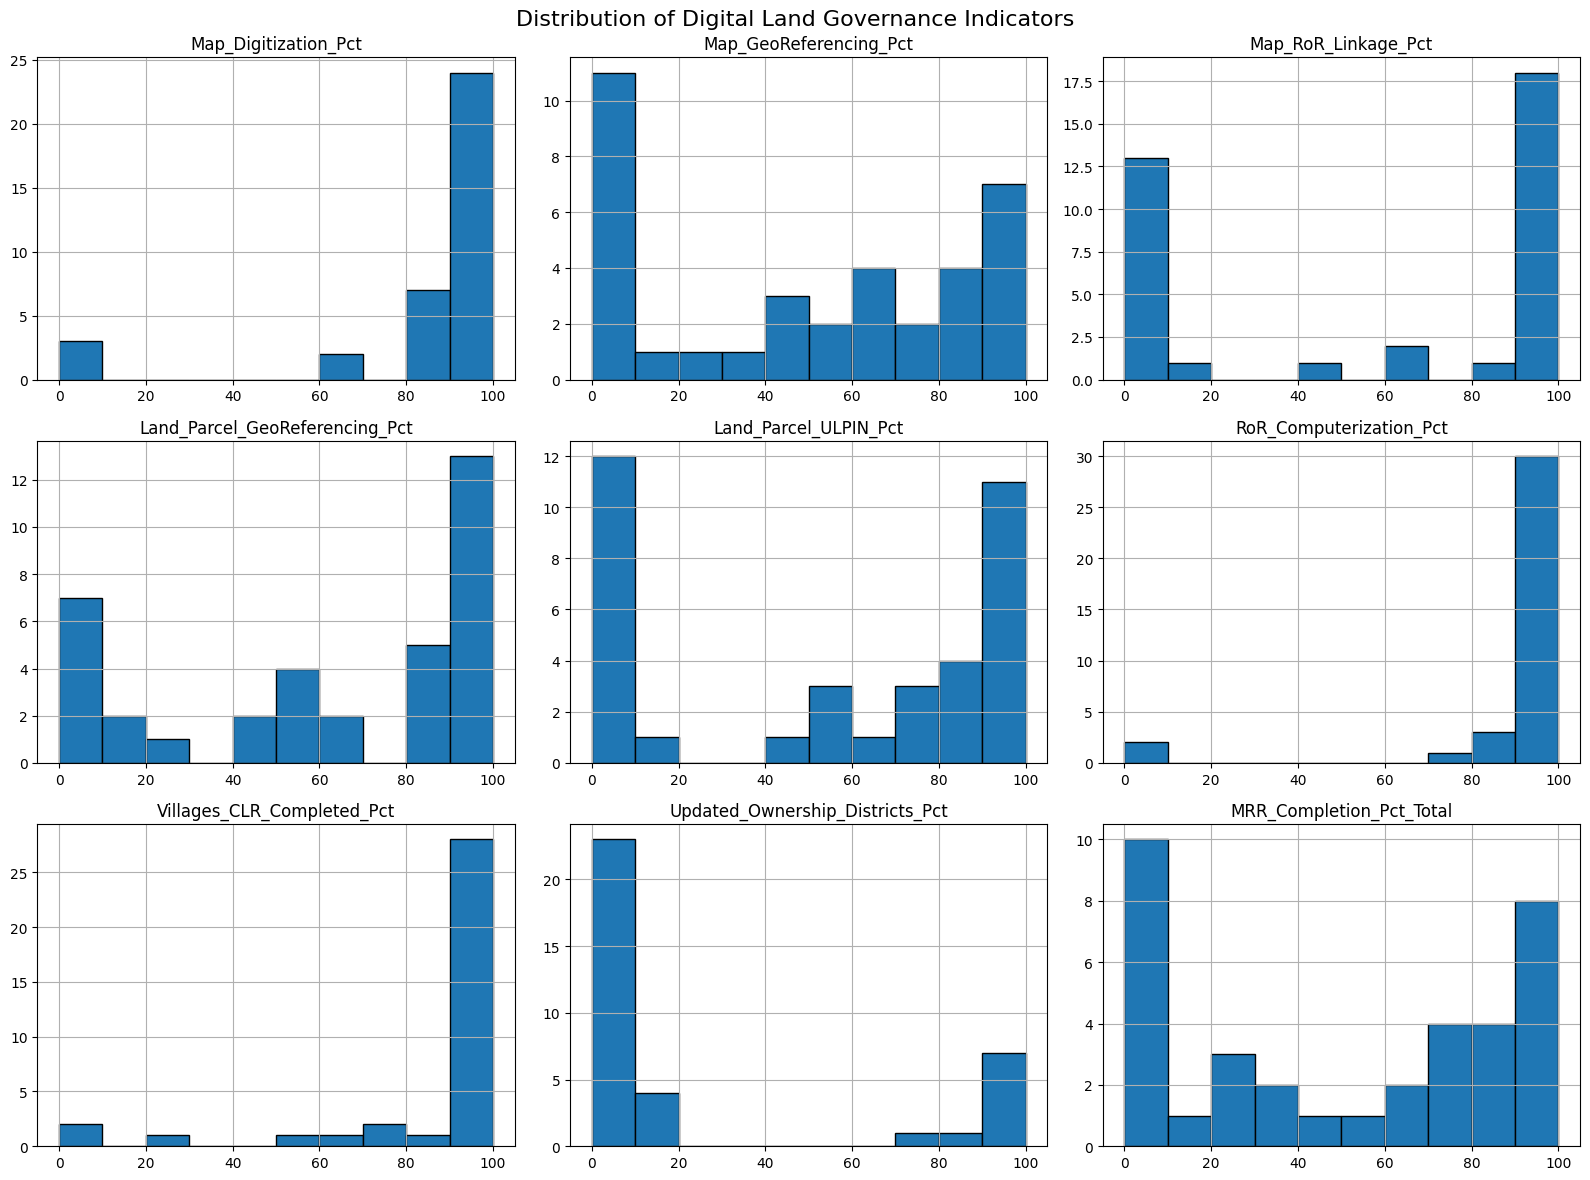

In [13]:
# ==========================================
# STEP 9: PERCENTAGE FEATURE DISTRIBUTIONS
# ==========================================

df[percentage_cols].hist(
    figsize=(16, 12),
    bins=10,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Digital Land Governance Indicators",
    fontsize=16
)

plt.tight_layout()
plt.show()

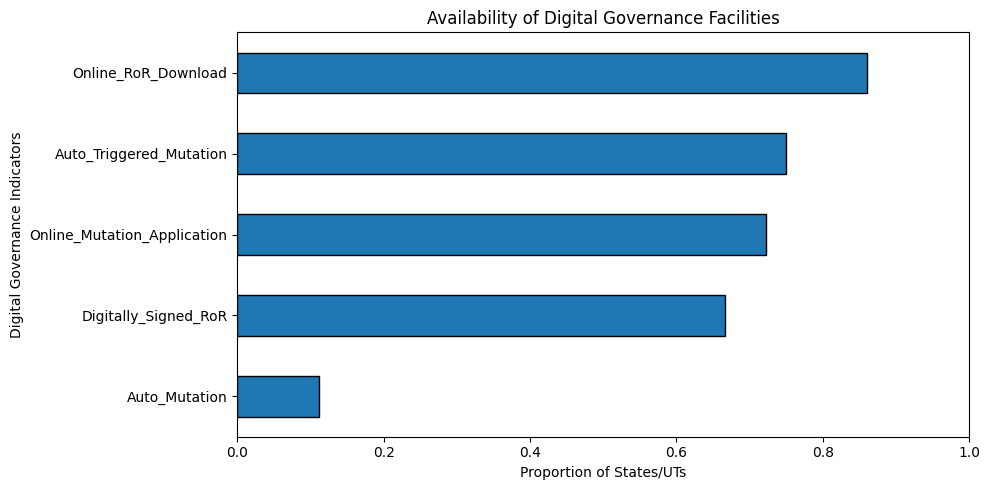

In [14]:
# ==========================================
# STEP 10: BINARY FEATURE DISTRIBUTIONS
# ==========================================

binary_prevalence = df[binary_cols].mean().sort_values()

plt.figure(figsize=(10, 5))

binary_prevalence.plot(
    kind="barh",
    edgecolor="black"
)

plt.xlabel("Proportion of States/UTs")
plt.ylabel("Digital Governance Indicators")

plt.title("Availability of Digital Governance Facilities")

plt.xlim(0, 1)

plt.tight_layout()
plt.show()

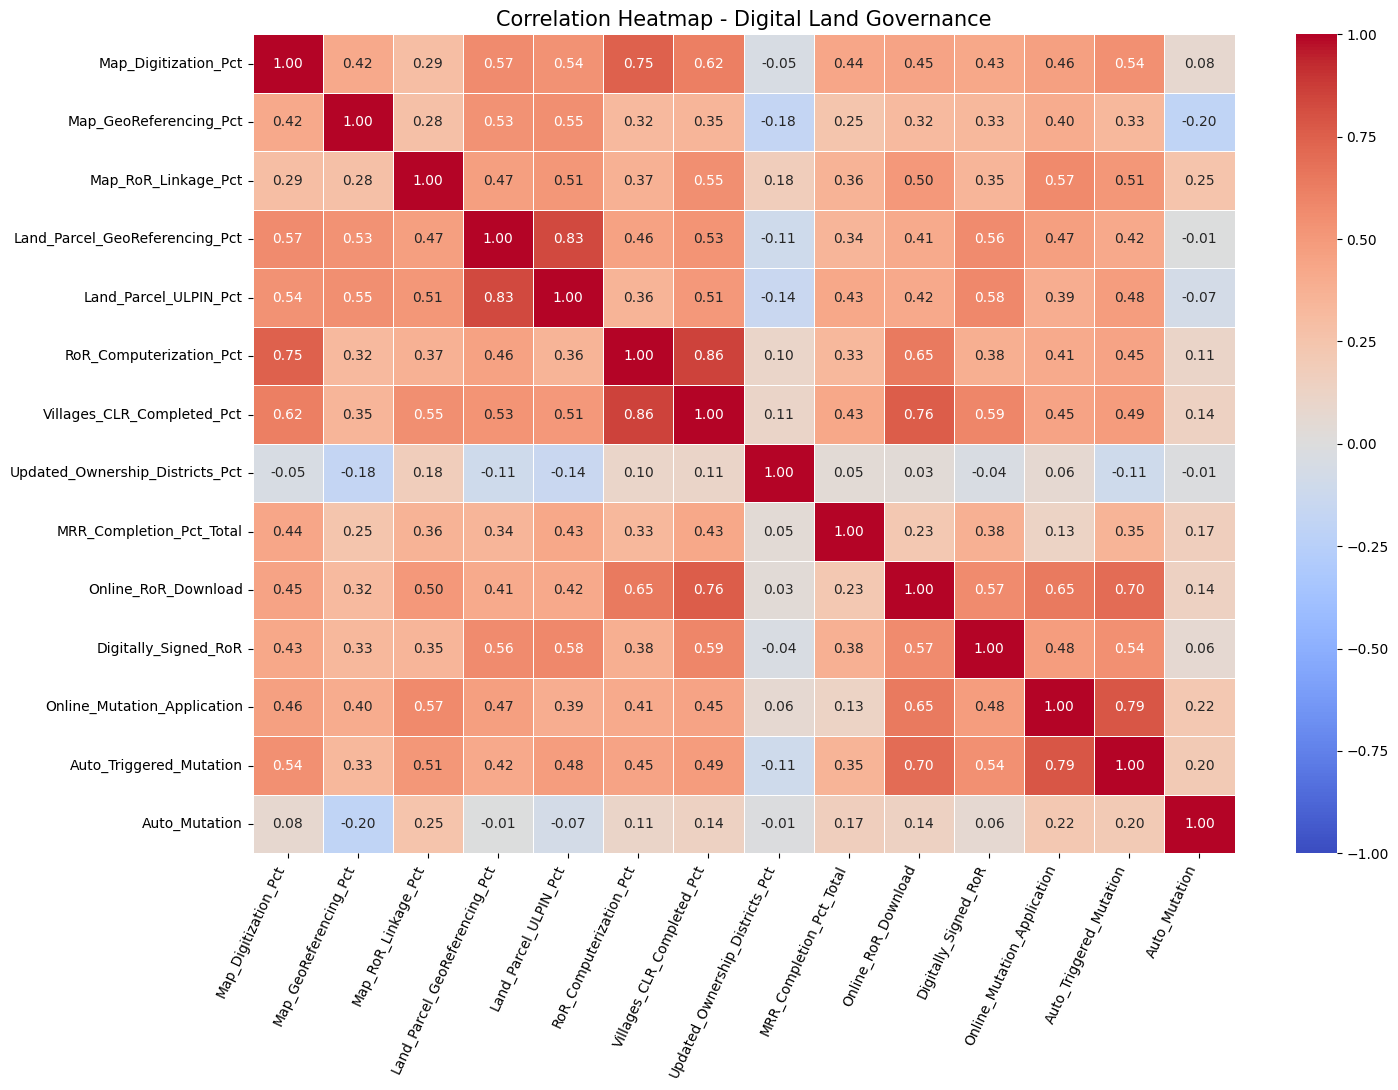

In [15]:
# ==========================================
# STEP 11: CORRELATION HEATMAP
# ==========================================

correlation_matrix = df[feature_cols].corr(
    method="pearson"
)

plt.figure(figsize=(15, 11))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title(
    "Correlation Heatmap - Digital Land Governance",
    fontsize=15
)

plt.xticks(rotation=65, ha="right")

plt.tight_layout()
plt.show()

In [16]:
# ==========================================
# STEP 12: CORRELATION ANALYSIS
# ==========================================

correlation_pairs = []

for i in range(len(feature_cols)):

    for j in range(i + 1, len(feature_cols)):

        col1 = feature_cols[i]
        col2 = feature_cols[j]

        corr_value = correlation_matrix.loc[
            col1, col2
        ]

        if abs(corr_value) >= 0.80:

            correlation_pairs.append({
                "Feature_1": col1,
                "Feature_2": col2,
                "Correlation": corr_value
            })

high_corr_df = pd.DataFrame(
    correlation_pairs
)

if not high_corr_df.empty:

    display(
        high_corr_df.sort_values(
            "Correlation",
            key=abs,
            ascending=False
        )
    )

else:
    print("No feature pairs above the correlation threshold.")

,Feature_1,Feature_2,Correlation
1,RoR_Computerization_Pct,Villages_CLR_Completed_Pct,0.858681
0,Land_Parcel_GeoReferencing_Pct,Land_Parcel_ULPIN_Pct,0.833964


In [17]:
# ==========================================
# STEP 13: EDA SUMMARY
# ==========================================

print("=" * 60)
print("DIGITAL LAND GOVERNANCE - EDA SUMMARY")
print("=" * 60)

print("Observations:", df.shape[0])
print("Total Columns:", df.shape[1])

print("Candidate Clustering Features:", len(feature_cols))
print("Percentage Features:", len(percentage_cols))
print("Binary Features:", len(binary_cols))

print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print(
    "Invalid Percentage Values:",
    percentage_validation["Invalid_Count"].sum()
)

print(
    "Highly Correlated Feature Pairs:",
    len(high_corr_df)
)

print("\nEDA EXECUTION COMPLETED")


DIGITAL LAND GOVERNANCE - EDA SUMMARY
Observations: 36
Total Columns: 17
Candidate Clustering Features: 14
Percentage Features: 9
Binary Features: 5
Missing Values: 0
Duplicate Rows: 0
Invalid Percentage Values: 0
Highly Correlated Feature Pairs: 2

EDA EXECUTION COMPLETED


#**Phase 2 Stats**

In [18]:
# ==========================================
# PHASE 2: FEATURE ENGINEERING & PREPROCESSING
# STEP 1: RELOAD AND VERIFY DATASETS
# ==========================================

import pandas as pd
import numpy as np
import os

from google.colab import files

# Upload datasets
uploaded = files.upload()

# File paths
csv_path = "DILRMP_Digital_Land_Governance_Clustering_Data.csv"
excel_path = "DILRMP_Digital_Land_Governance_Master_Dataset.xlsx"

# Verify uploaded files
assert os.path.exists(csv_path), "CSV file not found!"
assert os.path.exists(excel_path), "Excel file not found!"

# Load datasets
df_csv = pd.read_csv(csv_path)

df_excel = pd.read_excel(
    excel_path,
    sheet_name="Clustering_Dataset"
)

# Display basic information
print("CSV Dataset Shape:", df_csv.shape)
print("Excel Dataset Shape:", df_excel.shape)

print("\nCSV Columns:")
print(df_csv.columns.tolist())

print("\nExcel Columns:")
print(df_excel.columns.tolist())

# Verify dimensions and column order
assert df_csv.shape == df_excel.shape
assert df_csv.columns.tolist() == df_excel.columns.tolist()

# Verify State/UT order
assert df_csv["State_UT"].equals(df_excel["State_UT"])

# Compare numerical values independent of dtype
numeric_columns = df_csv.select_dtypes(
    include=np.number
).columns

assert np.allclose(
    df_csv[numeric_columns].to_numpy(dtype=float),
    df_excel[numeric_columns].to_numpy(dtype=float),
    equal_nan=True
)

# Verify missing values
print("\nCSV Missing Values:", df_csv.isnull().sum().sum())
print("Excel Missing Values:", df_excel.isnull().sum().sum())

print("\nDataset consistency verification: PASSED")

# Retain CSV as the primary working dataset
df_original = df_csv.copy(deep=True)

print("\nOriginal dataset preserved successfully.")

Saving DILRMP_Digital_Land_Governance_Clustering_Data.csv to DILRMP_Digital_Land_Governance_Clustering_Data (2).csv
Saving DILRMP_Digital_Land_Governance_Master_Dataset.xlsx to DILRMP_Digital_Land_Governance_Master_Dataset (2).xlsx
CSV Dataset Shape: (36, 17)
Excel Dataset Shape: (36, 17)

CSV Columns:
['State_UT', 'Total_Districts', 'Total_Villages', 'Map_Digitization_Pct', 'Map_GeoReferencing_Pct', 'Map_RoR_Linkage_Pct', 'Land_Parcel_GeoReferencing_Pct', 'Land_Parcel_ULPIN_Pct', 'RoR_Computerization_Pct', 'Villages_CLR_Completed_Pct', 'Updated_Ownership_Districts_Pct', 'MRR_Completion_Pct_Total', 'Online_RoR_Download', 'Digitally_Signed_RoR', 'Online_Mutation_Application', 'Auto_Triggered_Mutation', 'Auto_Mutation']

Excel Columns:
['State_UT', 'Total_Districts', 'Total_Villages', 'Map_Digitization_Pct', 'Map_GeoReferencing_Pct', 'Map_RoR_Linkage_Pct', 'Land_Parcel_GeoReferencing_Pct', 'Land_Parcel_ULPIN_Pct', 'RoR_Computerization_Pct', 'Villages_CLR_Completed_Pct', 'Updated_Ownershi

In [19]:
# ==========================================
# PHASE 2 - STEP 2
# FEATURE DEFINITION AUDIT
# ==========================================

import pandas as pd
import os

from google.colab import files

# Upload four official source workbooks
uploaded_sources = files.upload()

# Store uploaded filenames
source_files = list(uploaded_sources.keys())

print("Uploaded source files:")
for file in source_files:
    print("-", file)

# Inspect each workbook
for file in source_files:

    print("\n" + "=" * 80)
    print("FILE:", file)
    print("=" * 80)

    raw = pd.read_excel(file, header=None)

    print("\nWorkbook dimensions:", raw.shape)

    # Display title and header rows
    print("\nSOURCE HEADER STRUCTURE:")

    display(
        raw.iloc[:8].fillna("").T
    )

    print("\nFIRST THREE DATA RECORDS:")

    display(
        raw.iloc[8:11]
    )

Saving Computerization of Land Records (CLR) (1).xlsx to Computerization of Land Records (CLR) (1) (1).xlsx
Saving Modern Record Room (MRR).xlsx to Modern Record Room (MRR) (1).xlsx
Saving Survey-Re-Survey under NLRMP DILRMP (1).xlsx to Survey-Re-Survey under NLRMP DILRMP (1) (1).xlsx
Saving Map Digitization (1).xlsx to Map Digitization (1) (1).xlsx
Uploaded source files:
- Computerization of Land Records (CLR) (1) (1).xlsx
- Modern Record Room (MRR) (1).xlsx
- Survey-Re-Survey under NLRMP DILRMP (1) (1).xlsx
- Map Digitization (1) (1).xlsx

FILE: Computerization of Land Records (CLR) (1) (1).xlsx

Workbook dimensions: (47, 29)

SOURCE HEADER STRUCTURE:


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,0,1,2,3,4,5,6,7
0,Department of Land Resources,"Ministry of Rural Development, Government of I...",Digital India Land Records Modernization Progr...,Computerization of Land Records (CLR),,S.No.,,
1,,,,,,State/ UT,,
2,,,,,,Total Districts,,
3,,,,,,Total Tehsils,,
4,,,,,,Total Villages,,
5,,,,,,No. of RoR,Total,
6,,,,,,,Computerized,
7,,,,,,,%,
8,,,,,,,Linked with Cadastral Map,
9,,,,,,,%,



FIRST THREE DATA RECORDS:


,0,1,2,3,4,5,6,7,8,9,...,19,20,21,22,23,24,25,26,27,28
8,1,ANDAMAN & NICOBAR ISLANDS,3,9,205,"89,747","89,747",100.00,0,0.0,...,NO,YES,YES,NO,NO,0,0,NO,NO,NO
9,2,ANDHRA PRADESH,28,688,"17,605","3,26,17,293","3,26,17,293",100.00,0,0.0,...,YES,YES,YES,YES,NO,0,0,YES,YES,NO
10,3,ARUNACHAL PRADESH,27,72,"1,412",0,0,0.0,0,0.0,...,NO,NO,NO,NO,NO,0,0,NO,NO,NO



FILE: Modern Record Room (MRR) (1).xlsx

Workbook dimensions: (46, 10)

SOURCE HEADER STRUCTURE:


... (10 outputs left out)

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,0,1,2,3,4,5,6,7
0,Department of Land Resources,"Ministry of Rural Development, Government of I...",Digital India Land Records Modernization Progr...,Map Digitization,,S.No.,,
1,,,,,,State/ UT,,
2,,,,,,Total Districts,,
3,,,,,,Total Tehsils,,
4,,,,,,No. of Cadastral Maps / FMBs / Tippans,Cadastral Maps,Total
5,,,,,,,,Total Damaged/ Missing Maps
6,,,,,,,,Map in Good Condition
7,,,,,,,,Digitized
8,,,,,,,,% Digitized (of Total Cadastral Maps)
9,,,,,,,,% Digitized (of Maps in Good Condition)



FIRST THREE DATA RECORDS:


,0,1,2,3,4,5,6,7,8,9,...,24,25,26,27,28,29,30,31,32,33
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,1,ANDAMAN & NICOBAR ISLANDS,3,9,214,0,214,214,100.00,100.00,...,4,1.95,4,1.95,"89,790","4,017",4.47,"4,017",4.47,0
10,2,ANDHRA PRADESH,28,688,"14,725",0,"14,725","14,725",100.00,100.00,...,"7,950",45.16,"9,398",53.38,"1,30,66,287","1,30,66,287",100.00,"1,30,66,287",100.00,0


In [20]:
# ==========================================
# STEP 3: FEATURE CONFIGURATIONS
# ==========================================

# Identifier column
identifier = "State_UT"

# Exclude geographical size/context variables
context_features = [
    "Total_Districts",
    "Total_Villages"
]

# All 14 candidate clustering features
all_features = [
    "Map_Digitization_Pct",
    "Map_GeoReferencing_Pct",
    "Map_RoR_Linkage_Pct",
    "Land_Parcel_GeoReferencing_Pct",
    "Land_Parcel_ULPIN_Pct",
    "RoR_Computerization_Pct",
    "Villages_CLR_Completed_Pct",
    "Updated_Ownership_Districts_Pct",
    "MRR_Completion_Pct_Total",
    "Online_RoR_Download",
    "Digitally_Signed_RoR",
    "Online_Mutation_Application",
    "Auto_Triggered_Mutation",
    "Auto_Mutation"
]

# Model A: All 14 features
features_A = all_features.copy()

# Model B: Remove one feature from each
# highly correlated pair
features_B = [
    feature for feature in all_features
    if feature not in [
        "Villages_CLR_Completed_Pct",
        "Land_Parcel_ULPIN_Pct"
    ]
]

# Model C: Remove rare binary feature
features_C = [
    feature for feature in all_features
    if feature != "Auto_Mutation"
]

# Verify feature counts
feature_configurations = {
    "Model A - Baseline": features_A,
    "Model B - Correlation Reduced": features_B,
    "Model C - Rare Feature Sensitivity": features_C
}

for model_name, features in feature_configurations.items():
    print(f"\n{model_name}")
    print("Number of features:", len(features))
    print("Features:", features)

# Assertions
assert len(features_A) == 14
assert len(features_B) == 12
assert len(features_C) == 13

assert "State_UT" not in all_features
assert not any(
    feature in context_features
    for feature in all_features
)

print("\nAll feature configurations validated.")


Model A - Baseline
Number of features: 14
Features: ['Map_Digitization_Pct', 'Map_GeoReferencing_Pct', 'Map_RoR_Linkage_Pct', 'Land_Parcel_GeoReferencing_Pct', 'Land_Parcel_ULPIN_Pct', 'RoR_Computerization_Pct', 'Villages_CLR_Completed_Pct', 'Updated_Ownership_Districts_Pct', 'MRR_Completion_Pct_Total', 'Online_RoR_Download', 'Digitally_Signed_RoR', 'Online_Mutation_Application', 'Auto_Triggered_Mutation', 'Auto_Mutation']

Model B - Correlation Reduced
Number of features: 12
Features: ['Map_Digitization_Pct', 'Map_GeoReferencing_Pct', 'Map_RoR_Linkage_Pct', 'Land_Parcel_GeoReferencing_Pct', 'RoR_Computerization_Pct', 'Updated_Ownership_Districts_Pct', 'MRR_Completion_Pct_Total', 'Online_RoR_Download', 'Digitally_Signed_RoR', 'Online_Mutation_Application', 'Auto_Triggered_Mutation', 'Auto_Mutation']

Model C - Rare Feature Sensitivity
Number of features: 13
Features: ['Map_Digitization_Pct', 'Map_GeoReferencing_Pct', 'Map_RoR_Linkage_Pct', 'Land_Parcel_GeoReferencing_Pct', 'Land_Parce

In [21]:

# STEP 4: STANDARDIZATION USING STANDARD SCALER

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Preserve State/UT names separately (not used as clustering features)
state_names = df_original["State_UT"].copy()

# Preserve original, unscaled feature data for all three models
X_original_A = df_original[features_A].copy(deep=True)
X_original_B = df_original[features_B].copy(deep=True)
X_original_C = df_original[features_C].copy(deep=True)

# Create a separate StandardScaler for each model
scaler_A = StandardScaler()
scaler_B = StandardScaler()
scaler_C = StandardScaler()

# Fit and transform each model independently
X_scaled_A = pd.DataFrame(
    scaler_A.fit_transform(X_original_A),
    columns=features_A,
    index=df_original.index
)

X_scaled_B = pd.DataFrame(
    scaler_B.fit_transform(X_original_B),
    columns=features_B,
    index=df_original.index
)

X_scaled_C = pd.DataFrame(
    scaler_C.fit_transform(X_original_C),
    columns=features_C,
    index=df_original.index
)

# Store fitted scalers for future use
scalers = {
    "Model A": scaler_A,
    "Model B": scaler_B,
    "Model C": scaler_C
}

# Display dimensions
print("STANDARDIZATION COMPLETED")
print("-" * 50)

print("Model A:", X_scaled_A.shape)
print("Model B:", X_scaled_B.shape)
print("Model C:", X_scaled_C.shape)

print("\nModel A - Standardized Data (First 5 Rows)")
display(X_scaled_A.head())

print("\nModel B - Standardized Data (First 5 Rows)")
display(X_scaled_B.head())

print("\nModel C - Standardized Data (First 5 Rows)")
display(X_scaled_C.head())


STANDARDIZATION COMPLETED
--------------------------------------------------
Model A: (36, 14)
Model B: (36, 12)
Model C: (36, 13)

Model A - Standardized Data (First 5 Rows)


,Map_Digitization_Pct,Map_GeoReferencing_Pct,Map_RoR_Linkage_Pct,Land_Parcel_GeoReferencing_Pct,Land_Parcel_ULPIN_Pct,RoR_Computerization_Pct,Villages_CLR_Completed_Pct,Updated_Ownership_Districts_Pct,MRR_Completion_Pct_Total,Online_RoR_Download,Digitally_Signed_RoR,Online_Mutation_Application,Auto_Triggered_Mutation,Auto_Mutation
0,0.500002,-1.287168,0.941222,-1.498856,-1.209372,0.322160,0.484937,-0.642363,-1.312868,0.40161,-1.414214,0.620174,0.577350,-0.353553
1,0.500002,-0.310030,0.097050,1.005181,1.093628,0.322160,0.197716,-0.642363,-0.963289,0.40161,0.707107,0.620174,0.577350,2.828427
2,-3.117450,-1.287168,-1.247454,-1.616023,-1.317133,-4.038069,-3.294284,-0.642363,-1.312868,-2.48998,-1.414214,-1.612452,-1.732051,-0.353553
3,-0.021634,0.590858,0.281993,-0.149460,0.030965,-0.171854,0.111928,1.265416,-0.183459,0.40161,0.707107,0.620174,0.577350,-0.353553
4,0.500002,1.028768,0.593660,1.005181,1.093628,0.322160,0.484181,-0.642363,0.895013,0.40161,0.707107,0.620174,0.577350,-0.353553



Model B - Standardized Data (First 5 Rows)


,Map_Digitization_Pct,Map_GeoReferencing_Pct,Map_RoR_Linkage_Pct,Land_Parcel_GeoReferencing_Pct,RoR_Computerization_Pct,Updated_Ownership_Districts_Pct,MRR_Completion_Pct_Total,Online_RoR_Download,Digitally_Signed_RoR,Online_Mutation_Application,Auto_Triggered_Mutation,Auto_Mutation
0,0.500002,-1.287168,0.941222,-1.498856,0.322160,-0.642363,-1.312868,0.40161,-1.414214,0.620174,0.577350,-0.353553
1,0.500002,-0.310030,0.097050,1.005181,0.322160,-0.642363,-0.963289,0.40161,0.707107,0.620174,0.577350,2.828427
2,-3.117450,-1.287168,-1.247454,-1.616023,-4.038069,-0.642363,-1.312868,-2.48998,-1.414214,-1.612452,-1.732051,-0.353553
3,-0.021634,0.590858,0.281993,-0.149460,-0.171854,1.265416,-0.183459,0.40161,0.707107,0.620174,0.577350,-0.353553
4,0.500002,1.028768,0.593660,1.005181,0.322160,-0.642363,0.895013,0.40161,0.707107,0.620174,0.577350,-0.353553



Model C - Standardized Data (First 5 Rows)


,Map_Digitization_Pct,Map_GeoReferencing_Pct,Map_RoR_Linkage_Pct,Land_Parcel_GeoReferencing_Pct,Land_Parcel_ULPIN_Pct,RoR_Computerization_Pct,Villages_CLR_Completed_Pct,Updated_Ownership_Districts_Pct,MRR_Completion_Pct_Total,Online_RoR_Download,Digitally_Signed_RoR,Online_Mutation_Application,Auto_Triggered_Mutation
0,0.500002,-1.287168,0.941222,-1.498856,-1.209372,0.322160,0.484937,-0.642363,-1.312868,0.40161,-1.414214,0.620174,0.577350
1,0.500002,-0.310030,0.097050,1.005181,1.093628,0.322160,0.197716,-0.642363,-0.963289,0.40161,0.707107,0.620174,0.577350
2,-3.117450,-1.287168,-1.247454,-1.616023,-1.317133,-4.038069,-3.294284,-0.642363,-1.312868,-2.48998,-1.414214,-1.612452,-1.732051
3,-0.021634,0.590858,0.281993,-0.149460,0.030965,-0.171854,0.111928,1.265416,-0.183459,0.40161,0.707107,0.620174,0.577350
4,0.500002,1.028768,0.593660,1.005181,1.093628,0.322160,0.484181,-0.642363,0.895013,0.40161,0.707107,0.620174,0.577350


In [22]:

# STEP 5: VALIDATION OF STANDARDIZED DATASETS

import numpy as np
import pandas as pd

models = {
    "Model A": (X_original_A, X_scaled_A, features_A),
    "Model B": (X_original_B, X_scaled_B, features_B),
    "Model C": (X_original_C, X_scaled_C, features_C)
}

validation_results = []

for model_name, (original, scaled, expected_features) in models.items():

    # 1. Check dimensions
    dimensions_correct = (
        original.shape == scaled.shape == (36, len(expected_features))
    )

    # 2. Check feature names and order
    feature_order_correct = (
        list(scaled.columns) == expected_features
    )

    # 3. Check missing values
    missing_values = int(scaled.isnull().sum().sum())

    # 4. Check infinite values
    infinite_values = int(
        np.isinf(scaled.to_numpy()).sum()
    )

    # 5. Check standardized means
    maximum_absolute_mean = float(
        scaled.mean().abs().max()
    )

    # 6. Check standardized standard deviations
    maximum_std_difference = float(
        (scaled.std(ddof=0) - 1).abs().max()
    )

    # 7. Check original data was not modified
    original_preserved = np.array_equal(
        original.to_numpy(),
        df_original[expected_features].to_numpy()
    )

    # 8. Check identifiers are not included
    identifier_excluded = (
        "State_UT" not in scaled.columns
    )

    # 9. Check numerical data
    all_numeric = all(
        pd.api.types.is_numeric_dtype(dtype)
        for dtype in scaled.dtypes
    )

    # Overall validation
    passed = all([
        dimensions_correct,
        feature_order_correct,
        missing_values == 0,
        infinite_values == 0,
        maximum_absolute_mean < 1e-9,
        maximum_std_difference < 1e-9,
        original_preserved,
        identifier_excluded,
        all_numeric
    ])

    validation_results.append({
        "Model": model_name,
        "Dimensions Correct": dimensions_correct,
        "Feature Order Correct": feature_order_correct,
        "Missing Values": missing_values,
        "Infinite Values": infinite_values,
        "Maximum Absolute Mean": maximum_absolute_mean,
        "Maximum Std Difference": maximum_std_difference,
        "Original Data Preserved": original_preserved,
        "Identifier Excluded": identifier_excluded,
        "All Numeric": all_numeric,
        "Validation Status": "PASS" if passed else "FAIL"
    })

validation_df = pd.DataFrame(validation_results)

print("STANDARDIZATION VALIDATION REPORT")
print("=" * 80)

display(validation_df)

# Final validation assertion
assert all(
    result["Validation Status"] == "PASS"
    for result in validation_results
), "Validation failed. Review the results before proceeding."

print("\nAll three models passed the standardization validation.")


STANDARDIZATION VALIDATION REPORT


,Model,Dimensions Correct,Feature Order Correct,Missing Values,Infinite Values,Maximum Absolute Mean,Maximum Std Difference,Original Data Preserved,Identifier Excluded,All Numeric,Validation Status
0,Model A,True,True,0,0,6.830956e-16,6.661338e-16,True,True,True,PASS
1,Model B,True,True,0,0,3.238150e-16,6.661338e-16,True,True,True,PASS
2,Model C,True,True,0,0,6.830956e-16,6.661338e-16,True,True,True,PASS



All three models passed the standardization validation.


In [23]:

# STEP 6: EXPORT CLEANED AND STANDARDIZED DATASETS

import os
from google.colab import files

# Create an output directory
output_dir = "/content/preprocessed_datasets"
os.makedirs(output_dir, exist_ok=True)

# Prepare datasets for export
export_datasets = {
    "Cleaned_Digital_Land_Governance.csv": df_original,
    "Standardized_Model_A.csv": pd.concat(
        [state_names.reset_index(drop=True),
         X_scaled_A.reset_index(drop=True)], axis=1
    ),
    "Standardized_Model_B.csv": pd.concat(
        [state_names.reset_index(drop=True),
         X_scaled_B.reset_index(drop=True)], axis=1
    ),
    "Standardized_Model_C.csv": pd.concat(
        [state_names.reset_index(drop=True),
         X_scaled_C.reset_index(drop=True)], axis=1
    )
}

# Export each dataset
for filename, dataset in export_datasets.items():

    file_path = os.path.join(output_dir, filename)

    dataset.to_csv(file_path, index=False)

    print(
        f"Exported: {filename} | "
        f"Shape: {dataset.shape}"
    )

print("\nAll four datasets exported successfully.")

# Create a ZIP archive containing all four CSV files
import shutil

zip_path = shutil.make_archive(
    "/content/Digital_Land_Governance_Preprocessed_Datasets",
    "zip",
    output_dir
)

print("\nZIP archive created successfully.")

# Download the ZIP archive
files.download(zip_path)


Exported: Cleaned_Digital_Land_Governance.csv | Shape: (36, 17)
Exported: Standardized_Model_A.csv | Shape: (36, 15)
Exported: Standardized_Model_B.csv | Shape: (36, 13)
Exported: Standardized_Model_C.csv | Shape: (36, 14)

All four datasets exported successfully.

ZIP archive created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# ============================================================
# PHASE 3 — STEP 1
# LOAD AND VERIFY PREPROCESSED DATASETS
# ============================================================

import pandas as pd
import numpy as np
import zipfile
import io

from google.colab import files

# ------------------------------------------------------------
# 1. Upload ZIP archive
# ------------------------------------------------------------

print("Upload Digital_Land_Governance_Preprocessed_Datasets.zip")

uploaded = files.upload()

zip_filename = next(
    (name for name in uploaded if name.endswith(".zip")),
    None
)

if zip_filename is None:
    raise ValueError("Please upload the preprocessed ZIP archive.")

# ------------------------------------------------------------
# 2. Extract and load CSV files
# ------------------------------------------------------------

required_files = [
    "Cleaned_Digital_Land_Governance.csv",
    "Standardized_Model_A.csv",
    "Standardized_Model_B.csv",
    "Standardized_Model_C.csv"
]

with zipfile.ZipFile(io.BytesIO(uploaded[zip_filename])) as archive:

    available_files = archive.namelist()

    missing_files = [
        name for name in required_files
        if name not in available_files
    ]

    if missing_files:
        raise FileNotFoundError(
            f"Missing files in ZIP: {missing_files}"
        )

    dataframes = {
        name.replace(".csv", ""): pd.read_csv(
            archive.open(name)
        )
        for name in required_files
    }

# ------------------------------------------------------------
# 3. Assign datasets
# ------------------------------------------------------------

cleaned_df = dataframes["Cleaned_Digital_Land_Governance"]

model_a_df = dataframes["Standardized_Model_A"]
model_b_df = dataframes["Standardized_Model_B"]
model_c_df = dataframes["Standardized_Model_C"]

# ------------------------------------------------------------
# 4. Define intended feature configurations
# ------------------------------------------------------------

model_features = {

    "Model A": [
        "Map_Digitization_Pct",
        "Map_GeoReferencing_Pct",
        "Map_RoR_Linkage_Pct",
        "Land_Parcel_GeoReferencing_Pct",
        "Land_Parcel_ULPIN_Pct",
        "RoR_Computerization_Pct",
        "Villages_CLR_Completed_Pct",
        "Updated_Ownership_Districts_Pct",
        "MRR_Completion_Pct_Total",
        "Online_RoR_Download",
        "Digitally_Signed_RoR",
        "Online_Mutation_Application",
        "Auto_Triggered_Mutation",
        "Auto_Mutation"
    ],

    "Model B": [
        "Map_Digitization_Pct",
        "Map_GeoReferencing_Pct",
        "Map_RoR_Linkage_Pct",
        "Land_Parcel_GeoReferencing_Pct",
        "RoR_Computerization_Pct",
        "Updated_Ownership_Districts_Pct",
        "MRR_Completion_Pct_Total",
        "Online_RoR_Download",
        "Digitally_Signed_RoR",
        "Online_Mutation_Application",
        "Auto_Triggered_Mutation",
        "Auto_Mutation"
    ],

    "Model C": [
        "Map_Digitization_Pct",
        "Map_GeoReferencing_Pct",
        "Map_RoR_Linkage_Pct",
        "Land_Parcel_GeoReferencing_Pct",
        "Land_Parcel_ULPIN_Pct",
        "RoR_Computerization_Pct",
        "Villages_CLR_Completed_Pct",
        "Updated_Ownership_Districts_Pct",
        "MRR_Completion_Pct_Total",
        "Online_RoR_Download",
        "Digitally_Signed_RoR",
        "Online_Mutation_Application",
        "Auto_Triggered_Mutation"
    ]
}

# ------------------------------------------------------------
# 5. Separate identifiers and numerical features
# ------------------------------------------------------------

state_ids = cleaned_df["State_UT"].copy()

X_a = model_a_df[model_features["Model A"]].copy()
X_b = model_b_df[model_features["Model B"]].copy()
X_c = model_c_df[model_features["Model C"]].copy()

# ------------------------------------------------------------
# 6. Dataset verification
# ------------------------------------------------------------

datasets = {
    "Cleaned Dataset": cleaned_df,
    "Model A": model_a_df,
    "Model B": model_b_df,
    "Model C": model_c_df
}

for name, df in datasets.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Shape:", df.shape)
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Unique States/UTs:", df["State_UT"].nunique())

    print("\nData types:")
    print(df.dtypes.value_counts())

# ------------------------------------------------------------
# 7. Verify standardized feature matrices
# ------------------------------------------------------------

feature_matrices = {
    "Model A": X_a,
    "Model B": X_b,
    "Model C": X_c
}

print("\n\nSTANDARDIZATION VALIDATION")

for name, X in feature_matrices.items():

    print("\n", name)

    print("Observations:", X.shape[0])
    print("Features:", X.shape[1])

    print("Missing values:", X.isnull().sum().sum())

    print(
        "All numeric:",
        all(pd.api.types.is_numeric_dtype(dtype)
            for dtype in X.dtypes)
    )

    print(
        "All finite:",
        np.isfinite(X.to_numpy()).all()
    )

    print(
        "Maximum absolute mean:",
        X.mean().abs().max()
    )

    print(
        "Maximum population SD deviation from 1:",
        (X.std(ddof=0) - 1).abs().max()
    )

    print(
        "State order matches:",
        model_a_df["State_UT"].equals(
            {
                "Model A": model_a_df,
                "Model B": model_b_df,
                "Model C": model_c_df
            }[name]["State_UT"]
        )
    )

print("\nSTEP 1 DATA LOADING COMPLETED.")


Upload Digital_Land_Governance_Preprocessed_Datasets.zip


Saving Digital_Land_Governance_Preprocessed_Datasets.zip to Digital_Land_Governance_Preprocessed_Datasets (1).zip

Cleaned Dataset
Shape: (36, 17)
Missing values: 0
Duplicate rows: 0
Unique States/UTs: 36

Data types:
float64    11
int64       5
object      1
Name: count, dtype: int64

Model A
Shape: (36, 15)
Missing values: 0
Duplicate rows: 0
Unique States/UTs: 36

Data types:
float64    14
object      1
Name: count, dtype: int64

Model B
Shape: (36, 13)
Missing values: 0
Duplicate rows: 0
Unique States/UTs: 36

Data types:
float64    12
object      1
Name: count, dtype: int64

Model C
Shape: (36, 14)
Missing values: 0
Duplicate rows: 0
Unique States/UTs: 36

Data types:
float64    13
object      1
Name: count, dtype: int64


STANDARDIZATION VALIDATION

 Model A
Observations: 36
Features: 14
Missing values: 0
All numeric: True
All finite: True
Maximum absolute mean: 6.846375318521799e-16
Maximum population SD deviation from 1: 6.661338147750939e-16
State order matches: True

 Model B

In [2]:

# ============================================================
# PHASE 3 — STEP 2
# DEFINE CANDIDATE NUMBER OF CLUSTERS
# ============================================================

# Candidate K values
K_VALUES = range(2, 7)

# Reproducibility settings
RANDOM_STATE = 42
N_INIT = 20
MAX_ITER = 300

# Feature configurations
feature_matrices = {
    "Model A": X_a,
    "Model B": X_b,
    "Model C": X_c
}

# Display experimental configuration
print("=" * 55)
print("K-MEANS EXPERIMENT CONFIGURATION")
print("=" * 55)

print("\nCandidate K values:", list(K_VALUES))
print("Random State:", RANDOM_STATE)
print("Number of Initializations:", N_INIT)
print("Maximum Iterations:", MAX_ITER)

print("\nDataset configurations:")

for model_name, X in feature_matrices.items():

    print(
        f"{model_name}: "
        f"{X.shape[0]} observations, "
        f"{X.shape[1]} features"
    )

# Validate candidate range
assert min(K_VALUES) >= 2
assert max(K_VALUES) < len(X_a)

print("\nSTEP 2 CONFIGURATION COMPLETED.")


K-MEANS EXPERIMENT CONFIGURATION

Candidate K values: [2, 3, 4, 5, 6]
Random State: 42
Number of Initializations: 20
Maximum Iterations: 300

Dataset configurations:
Model A: 36 observations, 14 features
Model B: 36 observations, 12 features
Model C: 36 observations, 13 features

STEP 2 CONFIGURATION COMPLETED.


ELBOW METHOD - WCSS RESULTS
Model   Model A   Model B   Model C
K                                  
2      339.6465  296.2315  304.7327
3      274.3745  244.4645  237.2724
4      231.7204  205.1549  197.0289
5      190.6290  167.4617  172.8939
6      166.4940  143.2842  151.3645


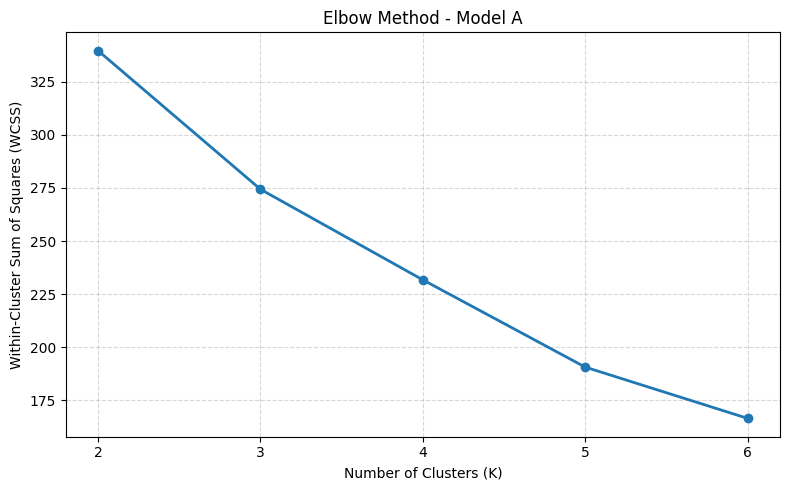

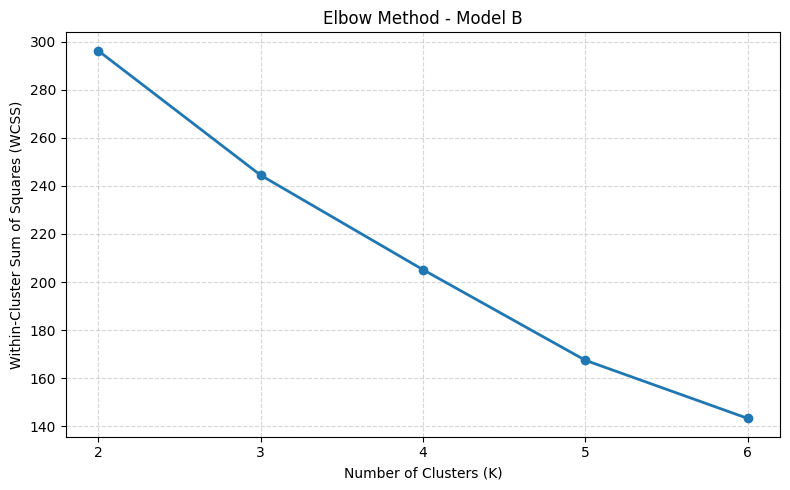

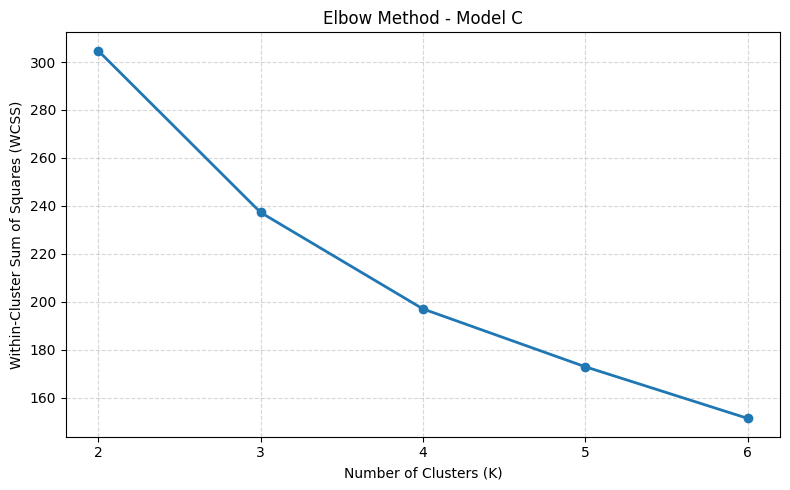


STEP 3 WCSS CALCULATION COMPLETED.


In [3]:

# ============================================================
# PHASE 3 — STEP 3
# ELBOW METHOD: WCSS CALCULATION
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans

# ------------------------------------------------------------
# 1. Store WCSS results
# ------------------------------------------------------------

wcss_results = []

# ------------------------------------------------------------
# 2. Fit K-Means for all models and candidate K values
# ------------------------------------------------------------

for model_name, X in feature_matrices.items():

    for k in K_VALUES:

        kmeans = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=N_INIT,
            max_iter=MAX_ITER
        )

        kmeans.fit(X)

        wcss_results.append({
            "Model": model_name,
            "K": k,
            "WCSS": kmeans.inertia_
        })

# ------------------------------------------------------------
# 3. Create WCSS comparison DataFrame
# ------------------------------------------------------------

wcss_df = pd.DataFrame(wcss_results)

print("=" * 65)
print("ELBOW METHOD - WCSS RESULTS")
print("=" * 65)

print(
    wcss_df.pivot(
        index="K",
        columns="Model",
        values="WCSS"
    ).round(4)
)

# ------------------------------------------------------------
# 4. Generate separate elbow plots
# ------------------------------------------------------------

for model_name in feature_matrices.keys():

    model_data = wcss_df[
        wcss_df["Model"] == model_name
    ]

    plt.figure(figsize=(8, 5))

    plt.plot(
        model_data["K"],
        model_data["WCSS"],
        marker="o",
        linewidth=2
    )

    plt.xticks(list(K_VALUES))

    plt.xlabel("Number of Clusters (K)")
    plt.ylabel("Within-Cluster Sum of Squares (WCSS)")

    plt.title(f"Elbow Method - {model_name}")

    plt.grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()

print("\nSTEP 3 WCSS CALCULATION COMPLETED.")


SILHOUETTE SCORE RESULTS
Model  Model A  Model B  Model C
K                               
2       0.3810   0.3769   0.4076
3       0.3116   0.2293   0.3410
4       0.2948   0.2727   0.3207
5       0.3252   0.3216   0.3314
6       0.3354   0.3350   0.3354


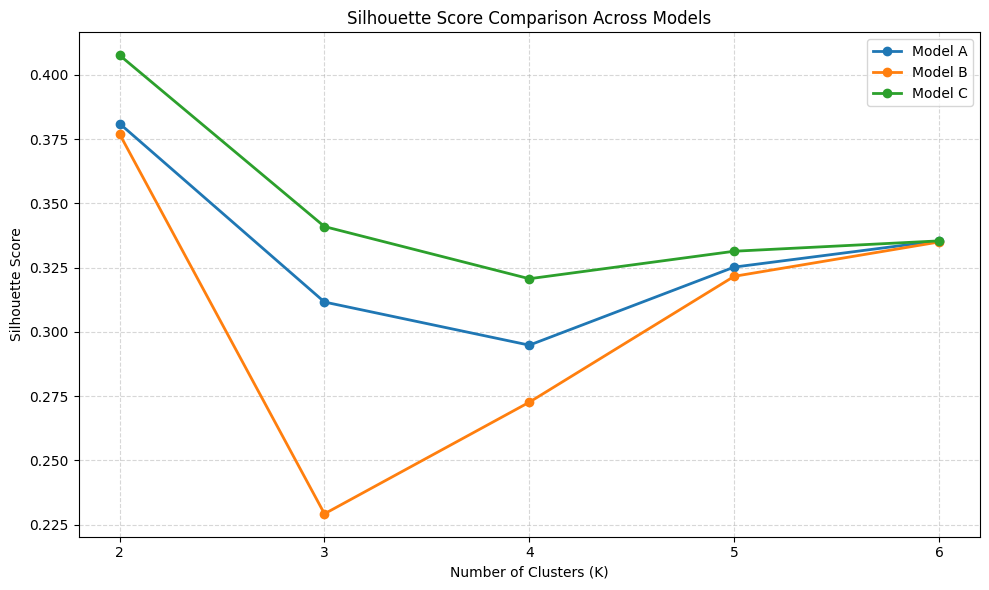


STEP 4 SILHOUETTE CALCULATION COMPLETED.


In [4]:

# ============================================================
# PHASE 3 — STEP 4
# SILHOUETTE SCORE CALCULATION
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ------------------------------------------------------------
# 1. Store silhouette results
# ------------------------------------------------------------

silhouette_results = []

# ------------------------------------------------------------
# 2. Calculate scores for all models and K values
# ------------------------------------------------------------

for model_name, X in feature_matrices.items():

    for k in K_VALUES:

        kmeans = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=N_INIT,
            max_iter=MAX_ITER
        )

        labels = kmeans.fit_predict(X)

        score = silhouette_score(
            X,
            labels,
            metric="euclidean"
        )

        silhouette_results.append({
            "Model": model_name,
            "K": k,
            "Silhouette_Score": score
        })

# ------------------------------------------------------------
# 3. Create comparison DataFrame
# ------------------------------------------------------------

silhouette_df = pd.DataFrame(silhouette_results)

print("=" * 65)
print("SILHOUETTE SCORE RESULTS")
print("=" * 65)

print(
    silhouette_df.pivot(
        index="K",
        columns="Model",
        values="Silhouette_Score"
    ).round(4)
)

# ------------------------------------------------------------
# 4. Visualize silhouette comparison
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for model_name in feature_matrices.keys():

    model_data = silhouette_df[
        silhouette_df["Model"] == model_name
    ]

    plt.plot(
        model_data["K"],
        model_data["Silhouette_Score"],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.xticks(list(K_VALUES))

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.title("Silhouette Score Comparison Across Models")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print("\nSTEP 4 SILHOUETTE CALCULATION COMPLETED.")


DAVIES-BOULDIN INDEX RESULTS


Model,Model A,Model B,Model C
K,,,
2,1.1889,1.2170,1.1524
3,1.2085,1.6130,1.1449
4,1.3411,1.3739,1.2947
5,1.2219,1.2396,1.0340
6,0.9966,1.0096,1.1742


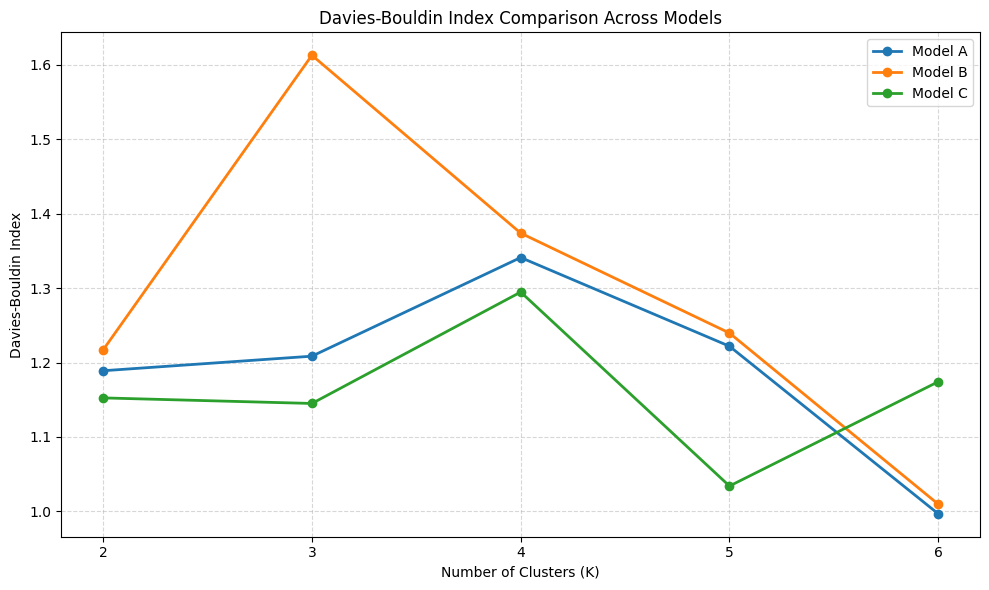


DBI calculation completed successfully.
Total configurations: 15


In [10]:
# ============================================================
# PHASE 3 — STEP 5
# DAVIES-BOULDIN INDEX CALCULATION
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score

# ------------------------------------------------------------
# 1. Store DBI results
# ------------------------------------------------------------

dbi_results = []

# ------------------------------------------------------------
# 2. Calculate DBI for all models and candidate K values
# ------------------------------------------------------------

for model_name, X in feature_matrices.items():

    for k in K_VALUES:

        kmeans = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=N_INIT,
            max_iter=MAX_ITER
        )

        labels = kmeans.fit_predict(X)

        score = davies_bouldin_score(
            X,
            labels
        )

        dbi_results.append({
            "Model": model_name,
            "K": k,
            "Davies_Bouldin_Index": score
        })

# ------------------------------------------------------------
# 3. Create DBI DataFrame
# ------------------------------------------------------------

dbi_df = pd.DataFrame(dbi_results)

# ------------------------------------------------------------
# 4. Display results
# ------------------------------------------------------------

print("=" * 70)
print("DAVIES-BOULDIN INDEX RESULTS")
print("=" * 70)

display(
    dbi_df.pivot(
        index="K",
        columns="Model",
        values="Davies_Bouldin_Index"
    ).round(4)
)

# ------------------------------------------------------------
# 5. Plot comparison
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for model_name in feature_matrices.keys():

    model_data = dbi_df[
        dbi_df["Model"] == model_name
    ]

    plt.plot(
        model_data["K"],
        model_data["Davies_Bouldin_Index"],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.xticks(list(K_VALUES))

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Davies-Bouldin Index")

plt.title("Davies-Bouldin Index Comparison Across Models")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Validate results
# ------------------------------------------------------------

assert len(dbi_results) == 15
assert dbi_df["Davies_Bouldin_Index"].notna().all()

print("\nDBI calculation completed successfully.")
print("Total configurations:", len(dbi_df))

In [11]:

# ============================================================
# PHASE 3 — STEP 6
# CONSOLIDATED MODEL COMPARISON
# ============================================================

# ------------------------------------------------------------
# 1. Merge all evaluation metrics
# ------------------------------------------------------------

comparison_df = (
    wcss_df
    .merge(
        silhouette_df,
        on=["Model", "K"]
    )
    .merge(
        dbi_df,
        on=["Model", "K"]
    )
)

# ------------------------------------------------------------
# 2. Add feature configuration information
# ------------------------------------------------------------

feature_counts = {
    "Model A": 14,
    "Model B": 12,
    "Model C": 13
}

comparison_df["Number_of_Features"] = (
    comparison_df["Model"].map(feature_counts)
)

# ------------------------------------------------------------
# 3. Arrange columns
# ------------------------------------------------------------

comparison_df = comparison_df[
    [
        "Model",
        "Number_of_Features",
        "K",
        "WCSS",
        "Silhouette_Score",
        "Davies_Bouldin_Index"
    ]
]

comparison_df = comparison_df.sort_values(
    by=["Model", "K"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 4. Display complete comparison
# ------------------------------------------------------------

print("=" * 90)
print("CONSOLIDATED K-MEANS MODEL EVALUATION")
print("=" * 90)

print(
    comparison_df.to_string(
        index=False,
        formatters={
            "WCSS": "{:.4f}".format,
            "Silhouette_Score": "{:.4f}".format,
            "Davies_Bouldin_Index": "{:.4f}".format
        }
    )
)

# ------------------------------------------------------------
# 5. Identify metric-wise leading configurations
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("BEST CONFIGURATION FOR EACH EVALUATION METRIC")
print("=" * 70)

best_silhouette = comparison_df.loc[
    comparison_df["Silhouette_Score"].idxmax()
]

best_dbi = comparison_df.loc[
    comparison_df["Davies_Bouldin_Index"].idxmin()
]

print("\nHighest Silhouette Score:")
print(best_silhouette.to_string())

print("\nLowest Davies-Bouldin Index:")
print(best_dbi.to_string())

# ------------------------------------------------------------
# 6. Display results by model
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL-WISE EVALUATION SUMMARY")
print("=" * 70)

for model_name in feature_counts:

    subset = comparison_df[
        comparison_df["Model"] == model_name
    ]

    print(f"\n{model_name}")

    print(
        "Best Silhouette K:",
        int(subset.loc[
            subset["Silhouette_Score"].idxmax(), "K"
        ])
    )

    print(
        "Best DBI K:",
        int(subset.loc[
            subset["Davies_Bouldin_Index"].idxmin(), "K"
        ])
    )

print("\nSTEP 6 MODEL COMPARISON COMPLETED.")


CONSOLIDATED K-MEANS MODEL EVALUATION
  Model  Number_of_Features  K     WCSS Silhouette_Score Davies_Bouldin_Index
Model A                  14  2 339.6465           0.3810               1.1889
Model A                  14  3 274.3745           0.3116               1.2085
Model A                  14  4 231.7204           0.2948               1.3411
Model A                  14  5 190.6290           0.3252               1.2219
Model A                  14  6 166.4940           0.3354               0.9966
Model B                  12  2 296.2315           0.3769               1.2170
Model B                  12  3 244.4645           0.2293               1.6130
Model B                  12  4 205.1549           0.2727               1.3739
Model B                  12  5 167.4617           0.3216               1.2396
Model B                  12  6 143.2842           0.3350               1.0096
Model C                  13  2 304.7327           0.4076               1.1524
Model C                  1

In [12]:

# ============================================================
# PHASE 3 — STEP 6A
# K-MEANS CLUSTER STABILITY ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

from itertools import combinations
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# ------------------------------------------------------------
# 1. Define stability experiment
# ------------------------------------------------------------

STABILITY_SEEDS = range(20)

stability_results = []

# ------------------------------------------------------------
# 2. Evaluate every model and candidate K
# ------------------------------------------------------------

for model_name, X in feature_matrices.items():

    for k in K_VALUES:

        all_labels = []

        # Fit K-Means using different random seeds
        for seed in STABILITY_SEEDS:

            kmeans = KMeans(
                n_clusters=k,
                random_state=seed,
                n_init=N_INIT,
                max_iter=MAX_ITER
            )

            labels = kmeans.fit_predict(X)

            all_labels.append(labels)

        # ----------------------------------------------------
        # 3. Calculate pairwise Adjusted Rand Index
        # ----------------------------------------------------

        ari_scores = []

        for i, j in combinations(
            range(len(all_labels)), 2
        ):

            ari = adjusted_rand_score(
                all_labels[i],
                all_labels[j]
            )

            ari_scores.append(ari)

        # ----------------------------------------------------
        # 4. Record stability statistics
        # ----------------------------------------------------

        stability_results.append({

            "Model": model_name,
            "K": k,

            "Mean_ARI": np.mean(ari_scores),

            "Std_ARI": np.std(
                ari_scores,
                ddof=0
            ),

            "Minimum_ARI": np.min(ari_scores),

            "Maximum_ARI": np.max(ari_scores)

        })

# ------------------------------------------------------------
# 5. Display stability results
# ------------------------------------------------------------

stability_df = pd.DataFrame(stability_results)

print("=" * 85)
print("K-MEANS CLUSTER STABILITY RESULTS")
print("=" * 85)

print(
    stability_df.to_string(
        index=False,
        formatters={
            "Mean_ARI": "{:.4f}".format,
            "Std_ARI": "{:.4f}".format,
            "Minimum_ARI": "{:.4f}".format,
            "Maximum_ARI": "{:.4f}".format
        }
    )
)

print("\nSTEP 6A STABILITY ANALYSIS COMPLETED.")


K-MEANS CLUSTER STABILITY RESULTS
  Model  K Mean_ARI Std_ARI Minimum_ARI Maximum_ARI
Model A  2   1.0000  0.0000      1.0000      1.0000
Model A  3   0.8305  0.1301      0.4654      1.0000
Model A  4   0.8024  0.1769      0.5051      1.0000
Model A  5   0.9701  0.0491      0.8037      1.0000
Model A  6   0.8734  0.0994      0.5427      1.0000
Model B  2   1.0000  0.0000      1.0000      1.0000
Model B  3   0.9375  0.0628      0.8301      1.0000
Model B  4   0.7895  0.1788      0.3615      1.0000
Model B  5   0.9760  0.0296      0.8945      1.0000
Model B  6   0.9347  0.0961      0.5685      1.0000
Model C  2   1.0000  0.0000      1.0000      1.0000
Model C  3   0.9210  0.1087      0.5924      1.0000
Model C  4   0.9166  0.0670      0.7616      1.0000
Model C  5   0.8555  0.1097      0.6014      1.0000
Model C  6   0.7010  0.1746      0.4777      1.0000

STEP 6A STABILITY ANALYSIS COMPLETED.


In [13]:

# ============================================================
# PHASE 3 — STEP 7
# TRAIN FINAL K-MEANS MODEL
# ============================================================

from sklearn.cluster import KMeans
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Define final model configuration
# ------------------------------------------------------------

FINAL_MODEL_NAME = "Model C"
FINAL_K = 2

X_final = X_c.copy()

# ------------------------------------------------------------
# 2. Train final K-Means model
# ------------------------------------------------------------

final_kmeans = KMeans(
    n_clusters=FINAL_K,
    random_state=RANDOM_STATE,
    n_init=N_INIT,
    max_iter=MAX_ITER
)

final_labels = final_kmeans.fit_predict(X_final)

# ------------------------------------------------------------
# 3. Create State/UT cluster assignment table
# ------------------------------------------------------------

cluster_assignments = pd.DataFrame({

    "State_UT": state_ids.values,

    "Cluster": final_labels

})

# Sort for easier interpretation
cluster_assignments = cluster_assignments.sort_values(
    by=["Cluster", "State_UT"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 4. Display cluster assignments
# ------------------------------------------------------------

print("=" * 65)
print("FINAL STATE/UT CLUSTER ASSIGNMENTS")
print("=" * 65)

print(cluster_assignments.to_string(index=False))

# ------------------------------------------------------------
# 5. Calculate cluster sizes
# ------------------------------------------------------------

cluster_sizes = (
    cluster_assignments["Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Number_of_States_UTs")
)

cluster_sizes["Percentage"] = (
    cluster_sizes["Number_of_States_UTs"]
    / len(cluster_assignments)
    * 100
)

print("\n" + "=" * 65)
print("CLUSTER SIZE DISTRIBUTION")
print("=" * 65)

print(cluster_sizes.to_string(
    index=False,
    formatters={
        "Percentage": "{:.2f}%".format
    }
))

# ------------------------------------------------------------
# 6. Validate final assignments
# ------------------------------------------------------------

assert len(cluster_assignments) == 36

assert cluster_assignments["State_UT"].nunique() == 36

assert cluster_assignments["Cluster"].nunique() == FINAL_K

assert cluster_assignments["Cluster"].notna().all()

assert set(cluster_assignments["Cluster"]) == {0, 1}

print("\nAll 36 States/UTs successfully assigned.")
print("Final K-Means model validation: PASSED")

print("\nSTEP 7 COMPLETED.")


FINAL STATE/UT CLUSTER ASSIGNMENTS
                                State_UT  Cluster
                       ARUNACHAL PRADESH        0
                                   DELHI        0
                                  LADAKH        0
                             LAKSHADWEEP        0
                               MEGHALAYA        0
                                 MIZORAM        0
                                NAGALAND        0
               ANDAMAN & NICOBAR ISLANDS        1
                          ANDHRA PRADESH        1
                                   ASSAM        1
                                   BIHAR        1
                              CHANDIGARH        1
                            CHHATTISGARH        1
DADRA AND NAGAR HAVELI AND DAMAN AND DIU        1
                                     GOA        1
                                 GUJARAT        1
                                 HARYANA        1
                        HIMACHAL PRADESH        1
               

In [14]:
# ============================================================
# PHASE 3 — STEP 8
# PCA: DIMENSIONALITY REDUCTION
# ============================================================

import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

# ------------------------------------------------------------
# 1. Verify selected Model C dataset
# ------------------------------------------------------------

print("=" * 65)
print("PCA INPUT VALIDATION")
print("=" * 65)

print("Dataset shape:", X_c.shape)
print("Number of features:", X_c.shape[1])
print("Number of observations:", X_c.shape[0])

assert X_c.shape == (36, 13), \
    "Unexpected Model C dimensions."

assert len(final_labels) == 36, \
    "Cluster labels do not match observations."

assert len(state_ids) == 36, \
    "State/UT identifiers do not match observations."

assert np.isfinite(X_c.to_numpy()).all(), \
    "Input contains invalid numerical values."

print("\nPCA input validation: PASSED")

# ------------------------------------------------------------
# 2. Apply PCA
# ------------------------------------------------------------

pca = PCA(n_components=2)

pca_coordinates = pca.fit_transform(X_c)

# ------------------------------------------------------------
# 3. Calculate explained variance
# ------------------------------------------------------------

explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(
    explained_variance
)

print("\n" + "=" * 65)
print("PCA EXPLAINED VARIANCE")
print("=" * 65)

print(
    f"PC1 Explained Variance: "
    f"{explained_variance[0] * 100:.2f}%"
)

print(
    f"PC2 Explained Variance: "
    f"{explained_variance[1] * 100:.2f}%"
)

print(
    f"Total Explained Variance: "
    f"{cumulative_variance[1] * 100:.2f}%"
)

# ------------------------------------------------------------
# 4. Create PCA results DataFrame
# ------------------------------------------------------------

pca_df = pd.DataFrame({

    "State_UT": state_ids.values,

    "PC1": pca_coordinates[:, 0],

    "PC2": pca_coordinates[:, 1],

    "Cluster": final_labels

})

# ------------------------------------------------------------
# 5. Display PCA results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PCA TRANSFORMED DATA")
print("=" * 65)

display(pca_df.head(10))

print("\nPCA output shape:", pca_df.shape)

print("\nSTEP 8 - PCA TRANSFORMATION COMPLETED.")

PCA INPUT VALIDATION
Dataset shape: (36, 13)
Number of features: 13
Number of observations: 36

PCA input validation: PASSED

PCA EXPLAINED VARIANCE
PC1 Explained Variance: 48.29%
PC2 Explained Variance: 10.92%
Total Explained Variance: 59.21%

PCA TRANSFORMED DATA


,State_UT,PC1,PC2,Cluster
0,ANDAMAN & NICOBAR ISLANDS,-0.653471,1.804482,1
1,ANDHRA PRADESH,1.396957,-0.613414,1
2,ARUNACHAL PRADESH,-7.212580,-1.606079,0
3,ASSAM,0.796491,0.800050,1
4,BIHAR,2.312408,-1.099346,1
5,CHANDIGARH,2.550000,-1.177700,1
6,CHHATTISGARH,1.722425,-0.239556,1
7,DADRA AND NAGAR HAVELI AND DAMAN AND DIU,-0.594406,-0.486282,1
8,DELHI,-2.458741,0.878807,0
9,GOA,1.588991,1.414152,1



PCA output shape: (36, 4)

STEP 8 - PCA TRANSFORMATION COMPLETED.


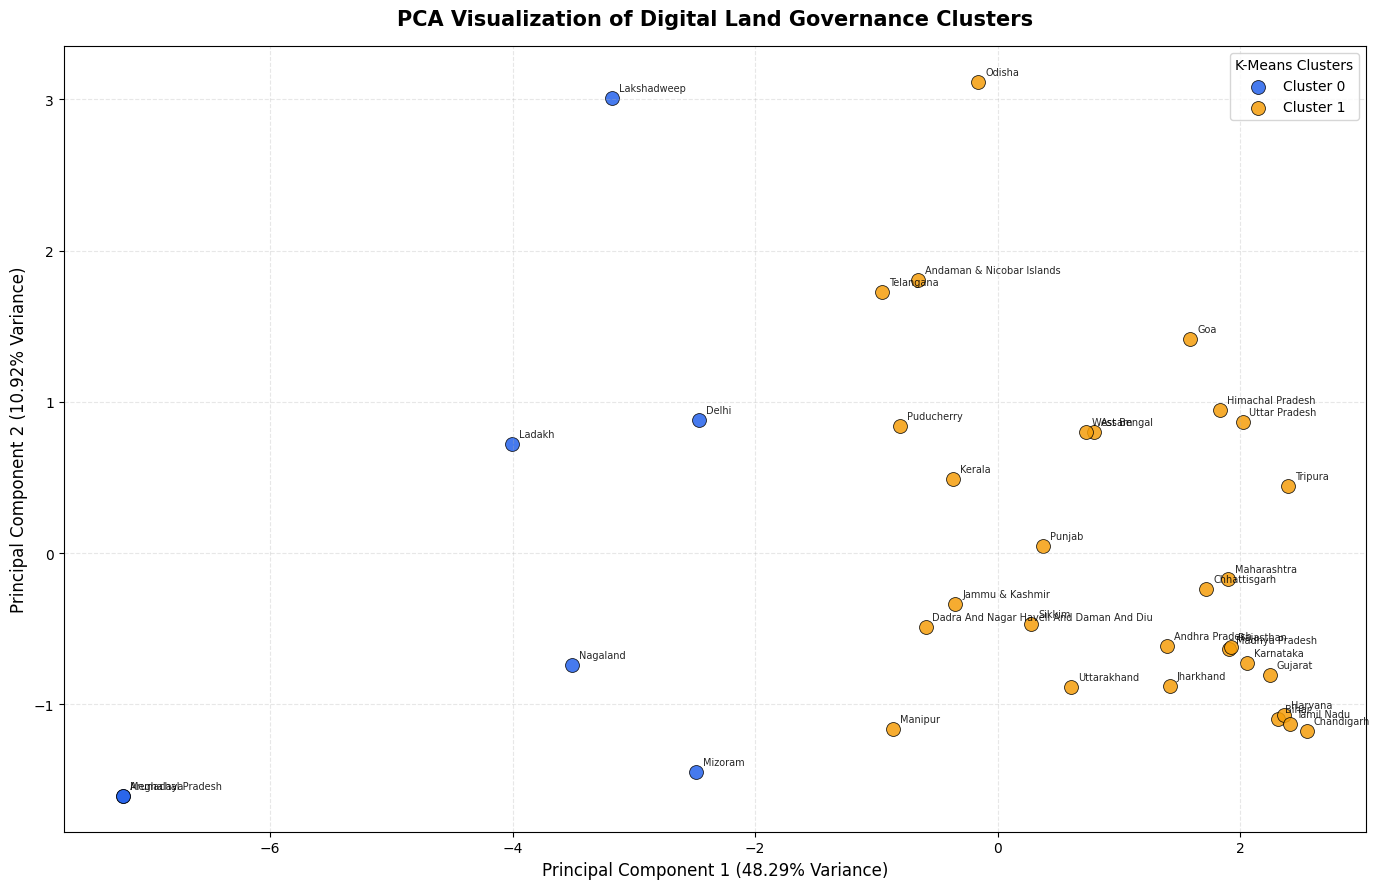

PCA visualization generated successfully.
Saved: PCA_Cluster_Visualization.png


In [15]:
# ============================================================
# PHASE 3 — STEP 9
# PCA TWO-DIMENSIONAL SCATTER VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Create figure
# ------------------------------------------------------------

plt.figure(figsize=(14, 9))

cluster_colors = {
    0: "#2563EB",
    1: "#F59E0B"
}

# ------------------------------------------------------------
# 2. Plot each cluster
# ------------------------------------------------------------

for cluster_id in sorted(pca_df["Cluster"].unique()):

    cluster_data = pca_df[
        pca_df["Cluster"] == cluster_id
    ]

    plt.scatter(
        cluster_data["PC1"],
        cluster_data["PC2"],
        label=f"Cluster {cluster_id}",
        color=cluster_colors[cluster_id],
        s=100,
        alpha=0.85,
        edgecolors="black",
        linewidths=0.6
    )

# ------------------------------------------------------------
# 3. Add State/UT labels
# ------------------------------------------------------------

for _, row in pca_df.iterrows():

    plt.annotate(
        row["State_UT"].title(),
        (row["PC1"], row["PC2"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=7,
        alpha=0.85
    )

# ------------------------------------------------------------
# 4. Configure axes and title
# ------------------------------------------------------------

plt.xlabel(
    f"Principal Component 1 "
    f"({explained_variance[0] * 100:.2f}% Variance)",
    fontsize=12
)

plt.ylabel(
    f"Principal Component 2 "
    f"({explained_variance[1] * 100:.2f}% Variance)",
    fontsize=12
)

plt.title(
    "PCA Visualization of Digital Land Governance Clusters",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.legend(
    title="K-Means Clusters",
    fontsize=10
)

plt.grid(
    True,
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

# ------------------------------------------------------------
# 5. Save visualization
# ------------------------------------------------------------

plt.savefig(
    "PCA_Cluster_Visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PCA visualization generated successfully.")
print("Saved: PCA_Cluster_Visualization.png")

In [16]:
# ============================================================
# PHASE 3 — STEP 10.1
# LOAD AND VALIDATE DATA FOR CLUSTER PROFILING
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Verify original cleaned dataset
# ------------------------------------------------------------

print("=" * 70)
print("CLUSTER PROFILING - DATA VALIDATION")
print("=" * 70)

assert "cleaned_df" in globals(), \
    "Original cleaned dataset not found."

assert "cluster_assignments" in globals(), \
    "Final cluster assignments not found."

assert cleaned_df.shape == (36, 17), \
    "Unexpected original dataset dimensions."

assert cluster_assignments["State_UT"].nunique() == 36, \
    "Duplicate State/UT assignments detected."

# ------------------------------------------------------------
# 2. Define Model C features
# ------------------------------------------------------------

profile_features = model_features["Model C"]

# Excluded columns
excluded_columns = [
    "State_UT",
    "Total_Districts",
    "Total_Villages"
]

# Validate feature selection
assert len(profile_features) == 13

assert not any(
    col in profile_features
    for col in excluded_columns
)

assert all(
    col in cleaned_df.columns
    for col in profile_features
)

# ------------------------------------------------------------
# 3. Separate percentage and binary indicators
# ------------------------------------------------------------

percentage_features = [
    col for col in profile_features
    if "_Pct" in col
]

binary_features = [
    col for col in profile_features
    if col not in percentage_features
]

print("\nPercentage indicators:", len(percentage_features))
print("Binary indicators:", len(binary_features))
print("Total profiling features:", len(profile_features))

# ------------------------------------------------------------
# 4. Create original unscaled profiling dataset
# ------------------------------------------------------------

profile_df = cleaned_df[
    ["State_UT"] + profile_features
].copy()

# ------------------------------------------------------------
# 5. Merge actual K-Means assignments
# ------------------------------------------------------------

profile_df = profile_df.merge(
    cluster_assignments,
    on="State_UT",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 6. Validate merged dataset
# ------------------------------------------------------------

assert profile_df.shape == (36, 15)

assert profile_df["Cluster"].notna().all()

assert profile_df["State_UT"].nunique() == 36

assert profile_df[profile_features].notna().all().all()

assert set(profile_df["Cluster"].unique()) == {0, 1}

# Verify binary indicators contain only 0 and 1
for col in binary_features:

    assert set(profile_df[col].unique()).issubset({0, 1}), \
        f"Invalid binary values in {col}"

# ------------------------------------------------------------
# 7. Display validation summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PROFILING DATASET VALIDATION")
print("=" * 70)

print("Original observations:", len(cleaned_df))
print("Merged observations:", len(profile_df))
print("Percentage indicators:", len(percentage_features))
print("Binary indicators:", len(binary_features))

print("\nCluster distribution:")

print(
    profile_df["Cluster"]
    .value_counts()
    .sort_index()
)

print("\nProfiling dataset preview:")

display(profile_df.head(10))

print("\nSTEP 10.1 COMPLETED SUCCESSFULLY.")

CLUSTER PROFILING - DATA VALIDATION

Percentage indicators: 9
Binary indicators: 4
Total profiling features: 13

PROFILING DATASET VALIDATION
Original observations: 36
Merged observations: 36
Percentage indicators: 9
Binary indicators: 4

Cluster distribution:
Cluster
0     7
1    29
Name: count, dtype: int64

Profiling dataset preview:


,State_UT,Map_Digitization_Pct,Map_GeoReferencing_Pct,Map_RoR_Linkage_Pct,Land_Parcel_GeoReferencing_Pct,Land_Parcel_ULPIN_Pct,RoR_Computerization_Pct,Villages_CLR_Completed_Pct,Updated_Ownership_Districts_Pct,MRR_Completion_Pct_Total,Online_RoR_Download,Digitally_Signed_RoR,Online_Mutation_Application,Auto_Triggered_Mutation,Cluster
0,ANDAMAN & NICOBAR ISLANDS,100.00,0.00,100.00,4.47,4.47,100.00,100.00,0.000000,0.00,1,0,1,1,1
1,ANDHRA PRADESH,100.00,37.42,61.43,100.00,100.00,100.00,92.40,0.000000,13.52,1,1,1,1,1
2,ARUNACHAL PRADESH,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.000000,0.00,0,0,0,0,0
3,ASSAM,85.58,71.92,69.88,55.95,55.92,88.67,90.13,77.142857,43.68,1,1,1,1,1
4,BIHAR,100.00,88.69,84.12,100.00,100.00,100.00,99.98,0.000000,85.39,1,1,1,1,1
5,CHANDIGARH,100.00,100.00,100.00,100.00,100.00,100.00,100.00,0.000000,100.00,1,1,1,1,1
6,CHHATTISGARH,99.68,42.57,97.21,81.58,81.58,100.00,99.74,0.000000,66.27,1,1,1,1,1
7,DADRA AND NAGAR HAVELI AND DAMAN AND DIU,100.00,66.54,49.48,50.02,50.02,100.00,100.00,0.000000,0.00,1,1,0,0,1
8,DELHI,80.33,10.14,3.24,0.00,0.00,88.91,27.31,14.285714,7.69,1,0,1,1,0
9,GOA,100.00,0.06,100.00,100.00,100.00,100.00,100.00,100.000000,33.33,1,1,1,1,1



STEP 10.1 COMPLETED SUCCESSFULLY.


In [17]:
# ============================================================
# PHASE 3 — STEP 10.2
# CLUSTER-WISE DESCRIPTIVE STATISTICS
# ============================================================

# ------------------------------------------------------------
# 1. Calculate cluster-wise statistics
# ------------------------------------------------------------

cluster_statistics = (
    profile_df
    .groupby("Cluster")[profile_features]
    .agg([
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

# ------------------------------------------------------------
# 2. Display percentage indicator statistics
# ------------------------------------------------------------

print("=" * 75)
print("CLUSTER-WISE PERCENTAGE INDICATOR STATISTICS")
print("=" * 75)

display(
    cluster_statistics[percentage_features]
    .round(2)
)

# ------------------------------------------------------------
# 3. Display binary indicator statistics
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CLUSTER-WISE BINARY INDICATOR STATISTICS")
print("=" * 75)

display(
    cluster_statistics[binary_features]
    .round(3)
)

# ------------------------------------------------------------
# 4. Calculate cluster sizes
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CLUSTER DISTRIBUTION")
print("=" * 75)

cluster_distribution = (
    profile_df["Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("State_UT_Count")
)

cluster_distribution["Percentage"] = (
    cluster_distribution["State_UT_Count"]
    / len(profile_df) * 100
)

display(cluster_distribution.round(2))

# ------------------------------------------------------------
# 5. Generate simplified cluster mean comparison
# ------------------------------------------------------------

cluster_mean_comparison = (
    profile_df
    .groupby("Cluster")[profile_features]
    .mean()
    .T
)

cluster_mean_comparison.columns = [
    f"Cluster_{col}" for col in cluster_mean_comparison.columns
]

cluster_mean_comparison["Difference_C0_minus_C1"] = (
    cluster_mean_comparison["Cluster_0"]
    - cluster_mean_comparison["Cluster_1"]
)

print("\n" + "=" * 75)
print("CLUSTER MEAN COMPARISON")
print("=" * 75)

display(cluster_mean_comparison.round(3))

print("\nSTEP 10.2 COMPLETED SUCCESSFULLY.")

CLUSTER-WISE PERCENTAGE INDICATOR STATISTICS


Map_Digitization_Pct                             \
                        mean median    std   min    max   
Cluster                                                   
0                      50.95  80.33  48.01   0.0  100.0   
1                      94.68  99.68  10.18  60.3  100.0   

        Map_GeoReferencing_Pct                             ...  \
                          mean median    std  min     max  ...   
Cluster                                                    ...   
0                        15.03   1.99  21.82  0.0   46.75  ...   
1                        57.56  66.07  37.67  0.0  100.00  ...   

        Updated_Ownership_Districts_Pct                            \
                                   mean median    std  min    max   
Cluster                                                             
0                                 32.40   12.5  46.57  0.0  100.0   
1                                 24.42    0.0  40.31  0.0  100.0   

        MRR_Completion_Pct_Total                             
                            mean median    std  min     max  
Cluster                                                      
0                          21.80   0.00  34.88  0.0   78.26  
1                          57.77  73.19  37.44  0.0  100.00  

[2 rows x 45 columns]


CLUSTER-WISE BINARY INDICATOR STATISTICS


Online_RoR_Download                       Digitally_Signed_RoR         \
                       mean median    std min max                 mean median   
Cluster                                                                         
0                     0.286    0.0  0.488   0   1                0.000    0.0   
1                     1.000    1.0  0.000   1   1                0.828    1.0   

                       Online_Mutation_Application                        \
           std min max                        mean median    std min max   
Cluster                                                                    
0        0.000   0   0                       0.143    0.0  0.378   0   1   
1        0.384   0   1                       0.862    1.0  0.351   0   1   

        Auto_Triggered_Mutation                        
                           mean median    std min max  
Cluster                                                
0                         0.143    0.0  0.378   0   1  
1                         0.897    1.0  0.310   0   1


CLUSTER DISTRIBUTION


,State_UT_Count,Percentage
Cluster,,
0,7,19.44
1,29,80.56



CLUSTER MEAN COMPARISON


,Cluster_0,Cluster_1,Difference_C0_minus_C1
Map_Digitization_Pct,50.953,94.681,-43.728
Map_GeoReferencing_Pct,15.026,57.564,-42.538
Map_RoR_Linkage_Pct,14.779,67.186,-52.408
Land_Parcel_GeoReferencing_Pct,16.114,72.644,-56.530
Land_Parcel_ULPIN_Pct,8.127,65.862,-57.735
RoR_Computerization_Pct,66.803,98.841,-32.038
Villages_CLR_Completed_Pct,44.761,97.404,-52.643
Updated_Ownership_Districts_Pct,32.398,24.424,7.974
MRR_Completion_Pct_Total,21.803,57.769,-35.966
Online_RoR_Download,0.286,1.000,-0.714



STEP 10.2 COMPLETED SUCCESSFULLY.


In [18]:
# ============================================================
# PHASE 3 — STEP 10.3
# IDENTIFY THE STRONGEST CLUSTER DIFFERENCES
# ============================================================

# ------------------------------------------------------------
# 1. Calculate cluster means
# ------------------------------------------------------------

cluster_means = (
    profile_df
    .groupby("Cluster")[profile_features]
    .mean()
)

# ------------------------------------------------------------
# 2. Prepare comparison table
# ------------------------------------------------------------

gap_analysis = []

for feature in profile_features:

    cluster_0_mean = cluster_means.loc[0, feature]
    cluster_1_mean = cluster_means.loc[1, feature]

    # Convert binary means into percentages
    if feature in binary_features:

        cluster_0_mean *= 100
        cluster_1_mean *= 100

        category = "Binary Adoption"

    else:

        category = "Percentage Coverage"

    difference = cluster_1_mean - cluster_0_mean

    gap_analysis.append({

        "Feature": feature,

        "Category": category,

        "Cluster_0_Mean": cluster_0_mean,

        "Cluster_1_Mean": cluster_1_mean,

        "Difference_C1_minus_C0": difference,

        "Absolute_Gap": abs(difference)

    })

# ------------------------------------------------------------
# 3. Create ranked gap analysis
# ------------------------------------------------------------

gap_analysis_df = pd.DataFrame(gap_analysis)

gap_analysis_df = (
    gap_analysis_df
    .sort_values(
        by="Absolute_Gap",
        ascending=False
    )
    .reset_index(drop=True)
)

gap_analysis_df.insert(
    0,
    "Gap_Rank",
    range(1, len(gap_analysis_df) + 1)
)

# ------------------------------------------------------------
# 4. Display ranked results
# ------------------------------------------------------------

print("=" * 85)
print("RANKED CLUSTER DIFFERENCES")
print("=" * 85)

display(
    gap_analysis_df.round(2)
)

# ------------------------------------------------------------
# 5. Identify the five strongest differences
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("TOP 5 INDICATORS DISTINGUISHING THE CLUSTERS")
print("=" * 85)

display(
    gap_analysis_df.head(5).round(2)
)

# ------------------------------------------------------------
# 6. Save gap analysis
# ------------------------------------------------------------

gap_analysis_df.to_csv(
    "Cluster_Gap_Analysis.csv",
    index=False
)

print("\nSaved: Cluster_Gap_Analysis.csv")

print("\nSTEP 10.3 COMPLETED SUCCESSFULLY.")

RANKED CLUSTER DIFFERENCES


,Gap_Rank,Feature,Category,Cluster_0_Mean,Cluster_1_Mean,Difference_C1_minus_C0,Absolute_Gap
0,1,Digitally_Signed_RoR,Binary Adoption,0.00,82.76,82.76,82.76
1,2,Auto_Triggered_Mutation,Binary Adoption,14.29,89.66,75.37,75.37
2,3,Online_Mutation_Application,Binary Adoption,14.29,86.21,71.92,71.92
3,4,Online_RoR_Download,Binary Adoption,28.57,100.00,71.43,71.43
4,5,Land_Parcel_ULPIN_Pct,Percentage Coverage,8.13,65.86,57.73,57.73
5,6,Land_Parcel_GeoReferencing_Pct,Percentage Coverage,16.11,72.64,56.53,56.53
6,7,Villages_CLR_Completed_Pct,Percentage Coverage,44.76,97.40,52.64,52.64
7,8,Map_RoR_Linkage_Pct,Percentage Coverage,14.78,67.19,52.41,52.41
8,9,Map_Digitization_Pct,Percentage Coverage,50.95,94.68,43.73,43.73
9,10,Map_GeoReferencing_Pct,Percentage Coverage,15.03,57.56,42.54,42.54



TOP 5 INDICATORS DISTINGUISHING THE CLUSTERS


,Gap_Rank,Feature,Category,Cluster_0_Mean,Cluster_1_Mean,Difference_C1_minus_C0,Absolute_Gap
0,1,Digitally_Signed_RoR,Binary Adoption,0.00,82.76,82.76,82.76
1,2,Auto_Triggered_Mutation,Binary Adoption,14.29,89.66,75.37,75.37
2,3,Online_Mutation_Application,Binary Adoption,14.29,86.21,71.92,71.92
3,4,Online_RoR_Download,Binary Adoption,28.57,100.00,71.43,71.43
4,5,Land_Parcel_ULPIN_Pct,Percentage Coverage,8.13,65.86,57.73,57.73



Saved: Cluster_Gap_Analysis.csv

STEP 10.3 COMPLETED SUCCESSFULLY.


In [19]:
# ============================================================
# PHASE 3 — STEP 10.4
# STATE/UT-LEVEL GOVERNANCE GAP IDENTIFICATION
# ============================================================

# ------------------------------------------------------------
# 1. Extract Cluster 0 and Cluster 1
# ------------------------------------------------------------

cluster_0_states = profile_df[
    profile_df["Cluster"] == 0
].copy()

cluster_1_states = profile_df[
    profile_df["Cluster"] == 1
].copy()

# ------------------------------------------------------------
# 2. Display actual Cluster 0 members
# ------------------------------------------------------------

print("=" * 85)
print("CLUSTER 0 - STATE/UT GOVERNANCE INDICATOR PROFILES")
print("=" * 85)

print("\nNumber of States/UTs:", len(cluster_0_states))

display(
    cluster_0_states[
        ["State_UT"] + profile_features
    ].reset_index(drop=True).round(2)
)

# ------------------------------------------------------------
# 3. Calculate descriptive percentage coverage
# ------------------------------------------------------------

cluster_0_states["Mean_Percentage_Coverage"] = (
    cluster_0_states[percentage_features].mean(axis=1)
)

cluster_0_states["Digital_Services_Enabled"] = (
    cluster_0_states[binary_features].sum(axis=1)
)

# ------------------------------------------------------------
# 4. Rank Cluster 0 members by percentage coverage
# ------------------------------------------------------------

priority_regions = (
    cluster_0_states[
        [
            "State_UT",
            "Mean_Percentage_Coverage",
            "Digital_Services_Enabled"
        ]
    ]
    .sort_values(
        by="Mean_Percentage_Coverage",
        ascending=True
    )
    .reset_index(drop=True)
)

priority_regions.insert(
    0,
    "Descriptive_Rank",
    range(1, len(priority_regions) + 1)
)

# ------------------------------------------------------------
# 5. Display descriptive ranking
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("CLUSTER 0 - DESCRIPTIVE COVERAGE COMPARISON")
print("=" * 85)

display(priority_regions.round(2))

# ------------------------------------------------------------
# 6. Identify the lowest percentage indicator
#    for each Cluster 0 member
# ------------------------------------------------------------

lowest_indicator_records = []

for _, row in cluster_0_states.iterrows():

    lowest_feature = row[percentage_features].idxmin()

    lowest_value = row[lowest_feature]

    lowest_indicator_records.append({

        "State_UT": row["State_UT"],

        "Lowest_Coverage_Indicator": lowest_feature,

        "Coverage_Percentage": lowest_value

    })

lowest_indicator_df = pd.DataFrame(
    lowest_indicator_records
)

print("\n" + "=" * 85)
print("LOWEST PERCENTAGE INDICATOR BY STATE/UT")
print("=" * 85)

display(lowest_indicator_df.round(2))

print("\nSTEP 10.4 COMPLETED SUCCESSFULLY.")

CLUSTER 0 - STATE/UT GOVERNANCE INDICATOR PROFILES

Number of States/UTs: 7


,State_UT,Map_Digitization_Pct,Map_GeoReferencing_Pct,Map_RoR_Linkage_Pct,Land_Parcel_GeoReferencing_Pct,Land_Parcel_ULPIN_Pct,RoR_Computerization_Pct,Villages_CLR_Completed_Pct,Updated_Ownership_Districts_Pct,MRR_Completion_Pct_Total,Online_RoR_Download,Digitally_Signed_RoR,Online_Mutation_Application,Auto_Triggered_Mutation
0,ARUNACHAL PRADESH,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0,0,0,0
1,DELHI,80.33,10.14,3.24,0.00,0.00,88.91,27.31,14.29,7.69,1,0,1,1
2,LADAKH,88.10,1.99,0.00,18.34,7.92,78.71,52.21,100.00,66.67,0,0,0,0
3,LAKSHADWEEP,0.00,0.00,100.00,0.00,0.00,100.00,100.00,100.00,0.00,1,0,0,0
4,MEGHALAYA,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0,0,0,0
5,MIZORAM,100.00,46.75,0.00,48.21,48.27,100.00,71.27,0.00,78.26,0,0,0,0
6,NAGALAND,88.24,46.30,0.21,46.25,0.70,100.00,62.54,12.50,0.00,0,0,0,0



CLUSTER 0 - DESCRIPTIVE COVERAGE COMPARISON


,Descriptive_Rank,State_UT,Mean_Percentage_Coverage,Digital_Services_Enabled
0,1,ARUNACHAL PRADESH,0.00,0
1,2,MEGHALAYA,0.00,0
2,3,DELHI,25.77,3
3,4,NAGALAND,39.64,0
4,5,LAKSHADWEEP,44.44,1
5,6,LADAKH,45.99,0
6,7,MIZORAM,54.75,0



LOWEST PERCENTAGE INDICATOR BY STATE/UT


,State_UT,Lowest_Coverage_Indicator,Coverage_Percentage
0,ARUNACHAL PRADESH,Map_Digitization_Pct,0.0
1,DELHI,Land_Parcel_GeoReferencing_Pct,0.0
2,LADAKH,Map_RoR_Linkage_Pct,0.0
3,LAKSHADWEEP,Map_Digitization_Pct,0.0
4,MEGHALAYA,Map_Digitization_Pct,0.0
5,MIZORAM,Map_RoR_Linkage_Pct,0.0
6,NAGALAND,MRR_Completion_Pct_Total,0.0



STEP 10.4 COMPLETED SUCCESSFULLY.


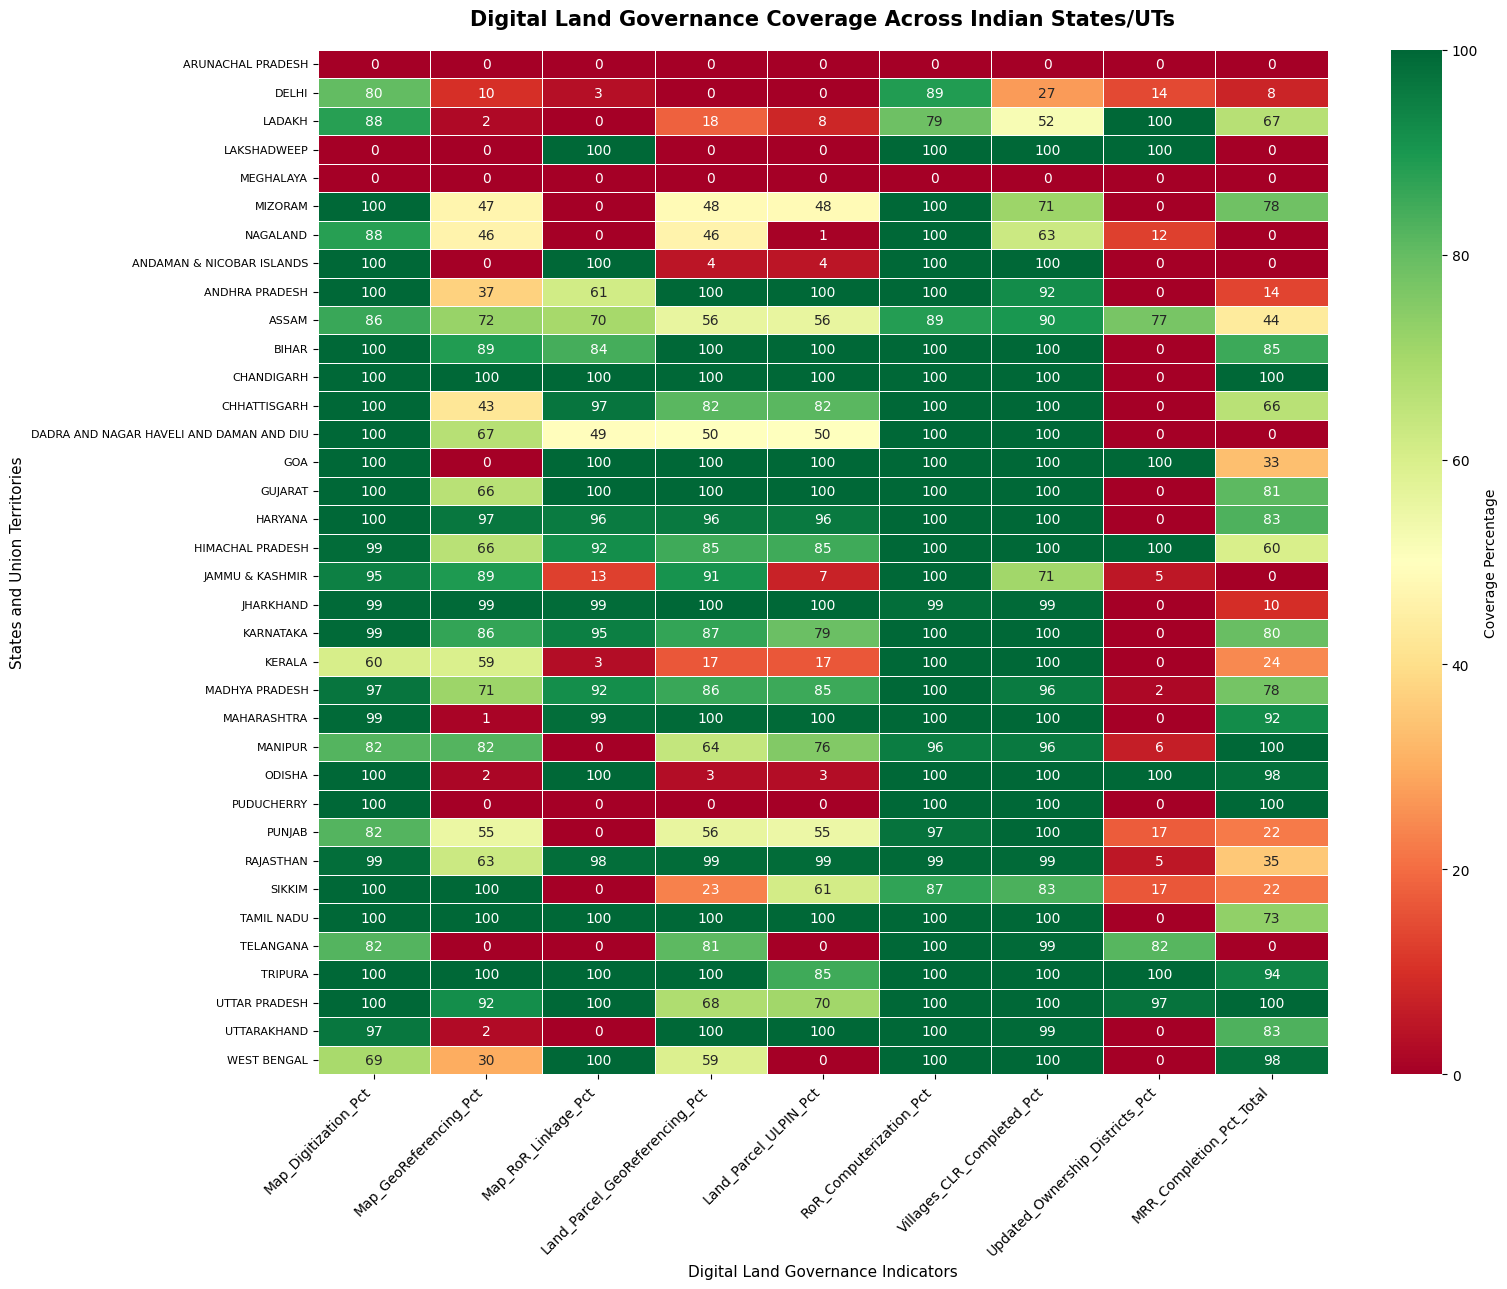

Heatmap generated successfully.
Saved: Governance_Indicator_Heatmap.png


In [20]:
# ============================================================
# PHASE 3 — STEP 10.5
# CLUSTER-WISE GOVERNANCE INDICATOR HEATMAP
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. Sort dataset by cluster and State/UT
# ------------------------------------------------------------

heatmap_df = profile_df.sort_values(
    by=["Cluster", "State_UT"]
).copy()

# ------------------------------------------------------------
# 2. Prepare percentage indicator matrix
# ------------------------------------------------------------

heatmap_data = heatmap_df.set_index(
    "State_UT"
)[percentage_features]

# ------------------------------------------------------------
# 3. Generate heatmap
# ------------------------------------------------------------

plt.figure(figsize=(16, 13))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
    linewidths=0.4,
    cbar_kws={
        "label": "Coverage Percentage"
    }
)

plt.title(
    "Digital Land Governance Coverage Across Indian States/UTs",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.xlabel(
    "Digital Land Governance Indicators",
    fontsize=11
)

plt.ylabel(
    "States and Union Territories",
    fontsize=11
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.yticks(
    fontsize=8
)

plt.tight_layout()

plt.savefig(
    "Governance_Indicator_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Heatmap generated successfully.")
print("Saved: Governance_Indicator_Heatmap.png")

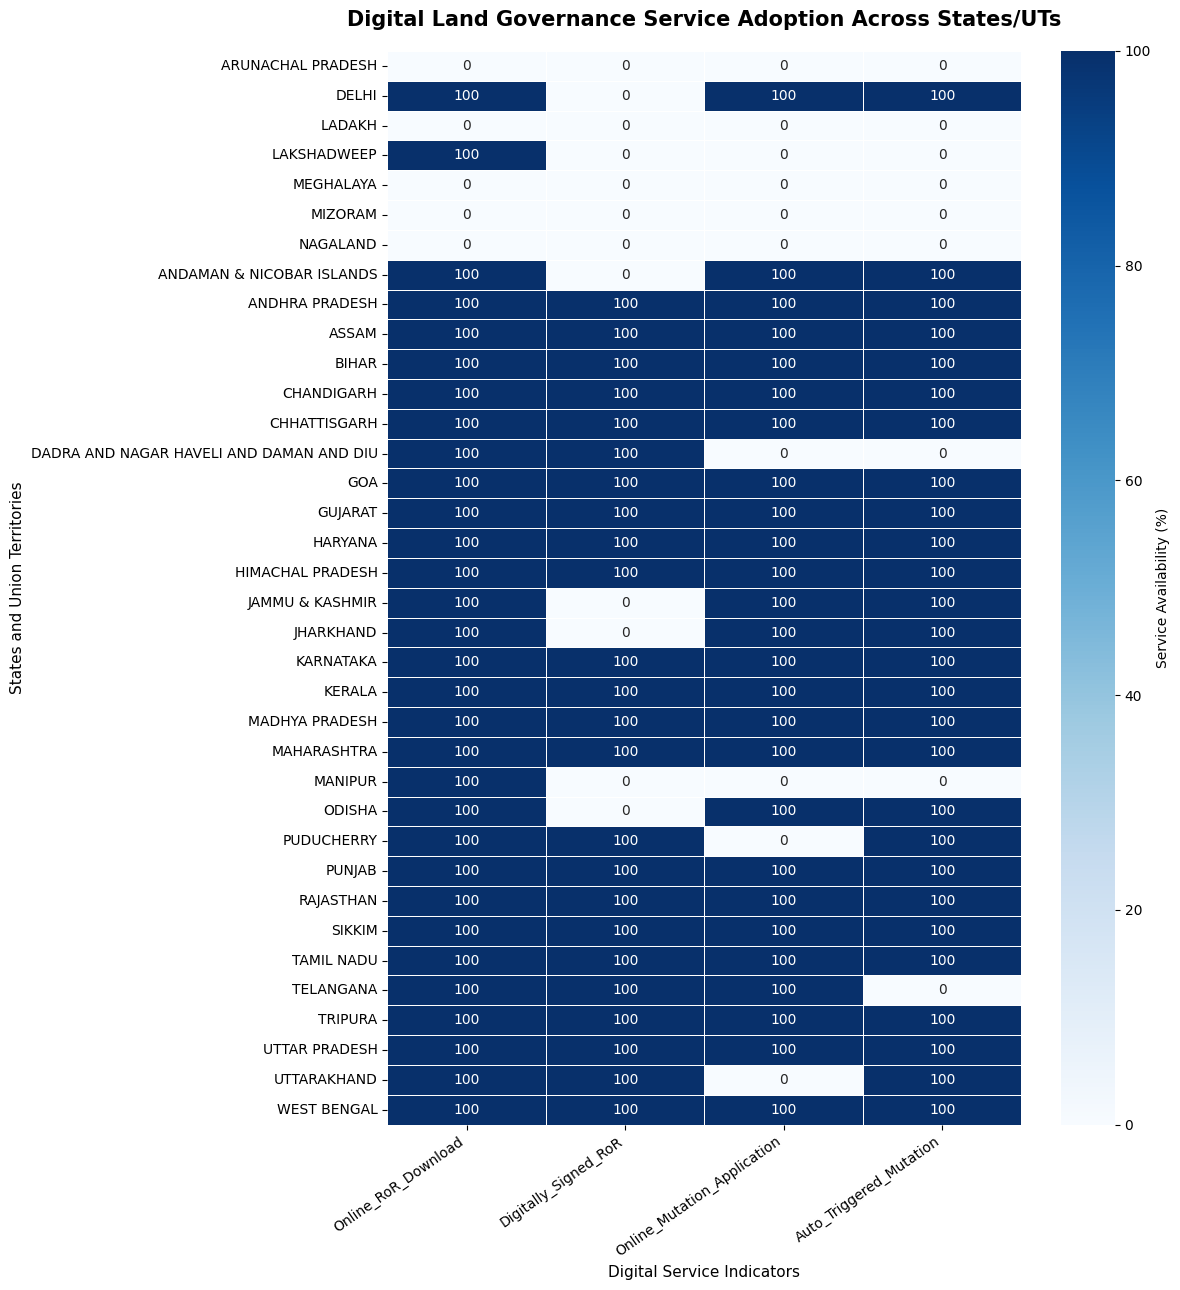

Binary service heatmap generated successfully.
Saved: Binary_Service_Adoption_Heatmap.png


In [21]:
# ============================================================
# PHASE 3 — STEP 10.6
# BINARY DIGITAL SERVICE ADOPTION HEATMAP
# ============================================================

# ------------------------------------------------------------
# 1. Prepare binary indicator data
# ------------------------------------------------------------

binary_heatmap = (
    profile_df
    .sort_values(["Cluster", "State_UT"])
    .set_index("State_UT")[binary_features]
)

# ------------------------------------------------------------
# 2. Generate visualization
# ------------------------------------------------------------

plt.figure(figsize=(12, 13))

sns.heatmap(
    binary_heatmap * 100,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={
        "label": "Service Availability (%)"
    }
)

plt.title(
    "Digital Land Governance Service Adoption Across States/UTs",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.xlabel("Digital Service Indicators", fontsize=11)
plt.ylabel("States and Union Territories", fontsize=11)

plt.xticks(rotation=35, ha="right")

plt.tight_layout()

plt.savefig(
    "Binary_Service_Adoption_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Binary service heatmap generated successfully.")
print("Saved: Binary_Service_Adoption_Heatmap.png")

In [23]:
# ============================================================
# DOWNLOAD ALL THREE PROJECT VISUALIZATIONS
# ============================================================

import os
import zipfile
from google.colab import files

output_files = [
    "PCA_Cluster_Visualization.png",
    "Governance_Indicator_Heatmap.png",
    "Binary_Service_Adoption_Heatmap.png"
]

# Verify files exist
for file in output_files:
    assert os.path.exists(file), f"Missing file: {file}"

# Create ZIP archive
zip_name = "Digital_Land_Governance_Visualizations.zip"

with zipfile.ZipFile(zip_name, "w") as zipf:
    for file in output_files:
        zipf.write(file)

print("All 3 visualizations verified.")
print("ZIP archive created successfully.")

# Download
files.download(zip_name)

All 3 visualizations verified.
ZIP archive created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
# ------------------------------------------------------------
# VERIFY STATE/UT ORDER ACROSS ALL DATASETS
# ------------------------------------------------------------

reference_state_order = (
    cleaned_df["State_UT"]
    .reset_index(drop=True)
)

for model_name, model_df in {
    "Model A": model_a_df,
    "Model B": model_b_df,
    "Model C": model_c_df
}.items():

    actual_state_order = (
        model_df["State_UT"]
        .reset_index(drop=True)
    )

    assert actual_state_order.equals(reference_state_order), (
        f"State/UT order mismatch in {model_name}"
    )

    print(f"{model_name}: State/UT order verified.")

print("\nAll State/UT orders match the cleaned dataset.")

Model A: State/UT order verified.
Model B: State/UT order verified.
Model C: State/UT order verified.

All State/UT orders match the cleaned dataset.


In [24]:
# ============================================================
# PHASE 4 — STEP 11.2
# GENERATE FINAL CLUSTER PROFILE CSV
# ============================================================

# ------------------------------------------------------------
# 1. Calculate cluster-wise feature means
# ------------------------------------------------------------

cluster_profile = (
    profile_df
    .groupby("Cluster")[profile_features]
    .mean()
    .reset_index()
)

# ------------------------------------------------------------
# 2. Add cluster size
# ------------------------------------------------------------

cluster_profile["State_UT_Count"] = (
    profile_df.groupby("Cluster")
    .size()
    .values
)

cluster_profile["Cluster_Percentage"] = (
    cluster_profile["State_UT_Count"]
    / len(profile_df) * 100
)

# ------------------------------------------------------------
# 3. Convert binary adoption rates into percentages
# ------------------------------------------------------------

for feature in binary_features:

    cluster_profile[feature] = (
        cluster_profile[feature] * 100
    )

# ------------------------------------------------------------
# 4. Arrange columns
# ------------------------------------------------------------

cluster_profile = cluster_profile[
    [
        "Cluster",
        "State_UT_Count",
        "Cluster_Percentage"
    ] + profile_features
]

# ------------------------------------------------------------
# 5. Validate results
# ------------------------------------------------------------

assert cluster_profile.shape == (2, 16)

assert cluster_profile["State_UT_Count"].sum() == 36

assert cluster_profile["Cluster"].tolist() == [0, 1]

assert cluster_profile[profile_features].notna().all().all()

# ------------------------------------------------------------
# 6. Export CSV
# ------------------------------------------------------------

profile_filename = "Final_Cluster_Profiles.csv"

cluster_profile.to_csv(
    profile_filename,
    index=False
)

# ------------------------------------------------------------
# 7. Display results
# ------------------------------------------------------------

print("=" * 75)
print("FINAL CLUSTER PROFILES")
print("=" * 75)

display(cluster_profile.round(2))

print("\nCSV export successful.")
print("Filename:", profile_filename)
print("Total clusters:", len(cluster_profile))
print("Total indicators:", len(profile_features))

print("\nSTEP 11.2 COMPLETED SUCCESSFULLY.")

FINAL CLUSTER PROFILES


,Cluster,State_UT_Count,Cluster_Percentage,Map_Digitization_Pct,Map_GeoReferencing_Pct,Map_RoR_Linkage_Pct,Land_Parcel_GeoReferencing_Pct,Land_Parcel_ULPIN_Pct,RoR_Computerization_Pct,Villages_CLR_Completed_Pct,Updated_Ownership_Districts_Pct,MRR_Completion_Pct_Total,Online_RoR_Download,Digitally_Signed_RoR,Online_Mutation_Application,Auto_Triggered_Mutation
0,0,7,19.44,50.95,15.03,14.78,16.11,8.13,66.80,44.76,32.40,21.80,28.57,0.00,14.29,14.29
1,1,29,80.56,94.68,57.56,67.19,72.64,65.86,98.84,97.40,24.42,57.77,100.00,82.76,86.21,89.66



CSV export successful.
Filename: Final_Cluster_Profiles.csv
Total clusters: 2
Total indicators: 13

STEP 11.2 COMPLETED SUCCESSFULLY.


In [25]:
# ============================================================
# PHASE 4 — STEP 11.3
# FINAL MODEL EVALUATION METRICS CSV
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. Convert existing lists into DataFrames
# ------------------------------------------------------------

wcss_df = pd.DataFrame(wcss_results)

silhouette_df = pd.DataFrame(silhouette_results)

dbi_df = pd.DataFrame(dbi_results)

stability_df = pd.DataFrame(stability_results)

# ------------------------------------------------------------
# 2. Merge evaluation metrics
# ------------------------------------------------------------

evaluation_metrics = (
    wcss_df
    .merge(
        silhouette_df,
        on=["Model", "K"],
        validate="one_to_one"
    )
    .merge(
        dbi_df,
        on=["Model", "K"],
        validate="one_to_one"
    )
    .merge(
        stability_df,
        on=["Model", "K"],
        validate="one_to_one"
    )
)

# ------------------------------------------------------------
# 3. Add feature counts
# ------------------------------------------------------------

feature_counts = {
    "Model A": 14,
    "Model B": 12,
    "Model C": 13
}

evaluation_metrics["Feature_Count"] = (
    evaluation_metrics["Model"].map(feature_counts)
)

# ------------------------------------------------------------
# 4. Arrange columns
# ------------------------------------------------------------

evaluation_metrics = evaluation_metrics[
    [
        "Model",
        "Feature_Count",
        "K",
        "WCSS",
        "Silhouette_Score",
        "Davies_Bouldin_Index",
        "Mean_ARI",
        "Std_ARI"
    ]
]

evaluation_metrics = (
    evaluation_metrics
    .sort_values(["Model", "K"])
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 5. Validate results
# ------------------------------------------------------------

assert evaluation_metrics.shape == (15, 8)

assert evaluation_metrics.notna().all().all()

assert evaluation_metrics.groupby("Model").size().eq(5).all()

assert evaluation_metrics["K"].nunique() == 5

assert set(evaluation_metrics["Model"].unique()) == {
    "Model A", "Model B", "Model C"
}

# ------------------------------------------------------------
# 6. Export CSV
# ------------------------------------------------------------

evaluation_filename = "Final_Model_Evaluation_Metrics.csv"

evaluation_metrics.to_csv(
    evaluation_filename,
    index=False
)

# ------------------------------------------------------------
# 7. Display results
# ------------------------------------------------------------

print("=" * 85)
print("FINAL MODEL EVALUATION METRICS")
print("=" * 85)

display(evaluation_metrics.round(4))

print("\nCSV export successful.")
print("Filename:", evaluation_filename)
print("Total configurations:", len(evaluation_metrics))

print("\nSTEP 11.3 COMPLETED SUCCESSFULLY.")

FINAL MODEL EVALUATION METRICS


,Model,Feature_Count,K,WCSS,Silhouette_Score,Davies_Bouldin_Index,Mean_ARI,Std_ARI
0,Model A,14,2,339.6465,0.3810,1.1889,1.0000,0.0000
1,Model A,14,3,274.3745,0.3116,1.2085,0.8305,0.1301
2,Model A,14,4,231.7204,0.2948,1.3411,0.8024,0.1769
3,Model A,14,5,190.6290,0.3252,1.2219,0.9701,0.0491
4,Model A,14,6,166.4940,0.3354,0.9966,0.8734,0.0994
5,Model B,12,2,296.2315,0.3769,1.2170,1.0000,0.0000
6,Model B,12,3,244.4645,0.2293,1.6130,0.9375,0.0628
7,Model B,12,4,205.1549,0.2727,1.3739,0.7895,0.1788
8,Model B,12,5,167.4617,0.3216,1.2396,0.9760,0.0296
9,Model B,12,6,143.2842,0.3350,1.0096,0.9347,0.0961



CSV export successful.
Filename: Final_Model_Evaluation_Metrics.csv
Total configurations: 15

STEP 11.3 COMPLETED SUCCESSFULLY.


In [26]:
# ============================================================
# PHASE 4 — STEP 11.4
# FINAL RESULTS VALIDATION
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Validate State/UT assignments
# ------------------------------------------------------------

assert len(final_assignment_df) == 36
assert final_assignment_df["State_UT"].nunique() == 36
assert final_assignment_df["Cluster"].notna().all()
assert not final_assignment_df.duplicated(
    subset=["State_UT"]
).any()

# ------------------------------------------------------------
# 2. Validate cluster distribution
# ------------------------------------------------------------

actual_sizes = (
    final_assignment_df
    .groupby("Cluster")
    .size()
    .sort_index()
)

profile_sizes = (
    cluster_profile
    .set_index("Cluster")["State_UT_Count"]
    .sort_index()
)

pd.testing.assert_series_equal(
    actual_sizes.astype(int),
    profile_sizes.astype(int),
    check_names=False
)

# Validate cluster percentages
actual_percentages = (
    final_assignment_df["Cluster"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

profile_percentages = (
    cluster_profile
    .set_index("Cluster")["Cluster_Percentage"]
    .sort_index()
)

assert np.allclose(
    actual_percentages.values,
    profile_percentages.values,
    atol=0.01
)

# ------------------------------------------------------------
# 3. Validate cluster profile
# ------------------------------------------------------------

expected_features = model_features["Model C"]

assert len(expected_features) == 13
assert cluster_profile.shape == (2, 16)
assert cluster_profile["Cluster"].nunique() == 2
assert cluster_profile.notna().all().all()

# ------------------------------------------------------------
# 4. Validate evaluation metrics
# ------------------------------------------------------------

assert evaluation_metrics.shape == (15, 8)

selected_model = evaluation_metrics[
    (evaluation_metrics["Model"] == "Model C") &
    (evaluation_metrics["K"] == 2)
]

assert len(selected_model) == 1

selected_row = selected_model.iloc[0]

assert np.isclose(
    selected_row["Silhouette_Score"], 0.4076, atol=0.0001
)

assert np.isclose(selected_row["Mean_ARI"], 1.0)
assert np.isclose(selected_row["Std_ARI"], 0.0)

# ------------------------------------------------------------
# 5. Display validation report
# ------------------------------------------------------------

print("=" * 65)
print("FINAL PROJECT RESULTS — VALIDATION REPORT")
print("=" * 65)

print("\n1. STATE/UT ASSIGNMENTS")
print("Total records:", len(final_assignment_df))
print("Unique States/UTs:", final_assignment_df["State_UT"].nunique())
print("Duplicate records: None")
print("Missing assignments: None")

print("\n2. CLUSTER DISTRIBUTION")

display(
    cluster_profile[
        ["Cluster", "State_UT_Count", "Cluster_Percentage"]
    ].round(2)
)

print("\n3. CLUSTER PROFILE")
print("Number of clusters:", cluster_profile["Cluster"].nunique())
print("Number of indicators:", len(expected_features))
print("Profile dimensions:", cluster_profile.shape)

print("\n4. SELECTED MODEL")
print("Model: Model C")
print("K: 2")
print("Features: 13")
print("Silhouette Score:", round(selected_row["Silhouette_Score"], 4))
print("Davies-Bouldin Index:", round(selected_row["Davies_Bouldin_Index"], 4))
print("Mean ARI:", round(selected_row["Mean_ARI"], 4))
print("Std ARI:", round(selected_row["Std_ARI"], 4))

print("\n" + "=" * 65)
print("ALL VALIDATION CHECKS PASSED SUCCESSFULLY.")
print("FINAL RESULTS ARE CONSISTENT.")
print("=" * 65)

FINAL PROJECT RESULTS — VALIDATION REPORT

1. STATE/UT ASSIGNMENTS
Total records: 36
Unique States/UTs: 36
Duplicate records: None
Missing assignments: None

2. CLUSTER DISTRIBUTION


,Cluster,State_UT_Count,Cluster_Percentage
0,0,7,19.44
1,1,29,80.56



3. CLUSTER PROFILE
Number of clusters: 2
Number of indicators: 13
Profile dimensions: (2, 16)

4. SELECTED MODEL
Model: Model C
K: 2
Features: 13
Silhouette Score: 0.4076
Davies-Bouldin Index: 1.1524
Mean ARI: 1.0
Std ARI: 0.0

ALL VALIDATION CHECKS PASSED SUCCESSFULLY.
FINAL RESULTS ARE CONSISTENT.


In [27]:
# Inspect actual columns in cluster_profile

print("CLUSTER PROFILE COLUMNS:")
print(cluster_profile.columns.tolist())

print("\nCLUSTER PROFILE DATA:")
display(cluster_profile.head())

print("\nCLUSTER PROFILE SHAPE:")
print(cluster_profile.shape)

CLUSTER PROFILE COLUMNS:
['Cluster', 'State_UT_Count', 'Cluster_Percentage', 'Map_Digitization_Pct', 'Map_GeoReferencing_Pct', 'Map_RoR_Linkage_Pct', 'Land_Parcel_GeoReferencing_Pct', 'Land_Parcel_ULPIN_Pct', 'RoR_Computerization_Pct', 'Villages_CLR_Completed_Pct', 'Updated_Ownership_Districts_Pct', 'MRR_Completion_Pct_Total', 'Online_RoR_Download', 'Digitally_Signed_RoR', 'Online_Mutation_Application', 'Auto_Triggered_Mutation']

CLUSTER PROFILE DATA:


,Cluster,State_UT_Count,Cluster_Percentage,Map_Digitization_Pct,Map_GeoReferencing_Pct,Map_RoR_Linkage_Pct,Land_Parcel_GeoReferencing_Pct,Land_Parcel_ULPIN_Pct,RoR_Computerization_Pct,Villages_CLR_Completed_Pct,Updated_Ownership_Districts_Pct,MRR_Completion_Pct_Total,Online_RoR_Download,Digitally_Signed_RoR,Online_Mutation_Application,Auto_Triggered_Mutation
0,0,7,19.444444,50.952857,15.025714,14.778571,16.114286,8.127143,66.802857,44.761429,32.397959,21.802857,28.571429,0.000000,14.285714,14.285714
1,1,29,80.555556,94.680690,57.564138,67.186207,72.643793,65.861724,98.841034,97.404483,24.424089,57.768621,100.000000,82.758621,86.206897,89.655172



CLUSTER PROFILE SHAPE:
(2, 16)


In [28]:
# ============================================================
# LANDINSIGHT — FINAL PROJECT FILES EXPORT
# Download all required files into one ZIP
# ============================================================

import os
import zipfile
from google.colab import files

# ------------------------------------------------------------
# 1. Create export directory
# ------------------------------------------------------------

export_folder = "/content/LANDINSIGHT_Project_Files"
os.makedirs(export_folder, exist_ok=True)

# ------------------------------------------------------------
# 2. List of required project files
# ------------------------------------------------------------

required_files = [
    "Final_State_UT_Cluster_Assignments.csv",
    "Final_Cluster_Profiles.csv",
    "Final_Model_Evaluation_Metrics.csv",
    "Cluster_Gap_Analysis.csv",
    "PCA_Cluster_Visualization.png",
    "Governance_Indicator_Heatmap.png",
    "Binary_Service_Adoption_Heatmap.png"
]

# ------------------------------------------------------------
# 3. Locate cleaned dataset
# ------------------------------------------------------------

# Add your cleaned dataset filename here if different.
cleaned_dataset_candidates = [
    "cleaned_dataset.csv",
    "cleaned_df.csv",
    "Cleaned_Dataset.csv",
    "cleaned_data.csv"
]

cleaned_dataset_found = None

for filename in cleaned_dataset_candidates:
    filepath = f"/content/{filename}"
    if os.path.exists(filepath):
        cleaned_dataset_found = filepath
        break

# ------------------------------------------------------------
# 4. Copy required files
# ------------------------------------------------------------

import shutil

copied_files = []
missing_files = []

for filename in required_files:
    source_path = f"/content/{filename}"

    if os.path.exists(source_path):
        shutil.copy2(
            source_path,
            os.path.join(export_folder, filename)
        )
        copied_files.append(filename)
    else:
        missing_files.append(filename)

# Copy cleaned dataset if found
if cleaned_dataset_found:
    filename = os.path.basename(cleaned_dataset_found)

    shutil.copy2(
        cleaned_dataset_found,
        os.path.join(export_folder, filename)
    )

    copied_files.append(filename)
else:
    print("WARNING: Cleaned dataset was not found automatically.")

# ------------------------------------------------------------
# 5. Copy current notebook if available
# ------------------------------------------------------------

print("\nNOTE: The current Colab notebook will be downloaded separately")
print("using File > Download > Download .ipynb if required.")

# ------------------------------------------------------------
# 6. Create ZIP archive
# ------------------------------------------------------------

zip_path = "/content/LANDINSIGHT_Project_Files.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:

    for filename in os.listdir(export_folder):
        filepath = os.path.join(export_folder, filename)

        zipf.write(
            filepath,
            arcname=filename
        )

# ------------------------------------------------------------
# 7. Display export summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("LANDINSIGHT — EXPORT SUMMARY")
print("=" * 60)

print("\nSuccessfully copied files:")

for filename in copied_files:
    print("✓", filename)

print("\nMissing files:")

if missing_files:
    for filename in missing_files:
        print("✗", filename)
else:
    print("None")

print("\nZIP FILE:", zip_path)
print("ZIP SIZE:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

print("\nEXPORT COMPLETED.")

# ------------------------------------------------------------
# 8. Download ZIP to local computer
# ------------------------------------------------------------

files.download(zip_path)


NOTE: The current Colab notebook will be downloaded separately
using File > Download > Download .ipynb if required.

LANDINSIGHT — EXPORT SUMMARY

Successfully copied files:
✓ Final_State_UT_Cluster_Assignments.csv
✓ Final_Cluster_Profiles.csv
✓ Final_Model_Evaluation_Metrics.csv
✓ Cluster_Gap_Analysis.csv
✓ PCA_Cluster_Visualization.png
✓ Governance_Indicator_Heatmap.png
✓ Binary_Service_Adoption_Heatmap.png

Missing files:
None

ZIP FILE: /content/LANDINSIGHT_Project_Files.zip
ZIP SIZE: 1.53 MB

EXPORT COMPLETED.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
# ============================================================
# LANDINSIGHT — COMPLETE PROJECT DATA EXPORT
# ============================================================

import os
import shutil
import zipfile
from google.colab import files

# ------------------------------------------------------------
# 1. Create a fresh export directory
# ------------------------------------------------------------

export_folder = "/content/LANDINSIGHT_Project_Files"

if os.path.exists(export_folder):
    shutil.rmtree(export_folder)

os.makedirs(export_folder)

# ------------------------------------------------------------
# 2. Define required output files
# ------------------------------------------------------------

required_files = [
    "Final_State_UT_Cluster_Assignments.csv",
    "Final_Cluster_Profiles.csv",
    "Final_Model_Evaluation_Metrics.csv",
    "Cluster_Gap_Analysis.csv",
    "PCA_Cluster_Visualization.png",
    "Governance_Indicator_Heatmap.png",
    "Binary_Service_Adoption_Heatmap.png"
]

copied_files = []
missing_files = []

# ------------------------------------------------------------
# 3. Copy final analytical outputs
# ------------------------------------------------------------

for filename in required_files:

    source_path = os.path.join("/content", filename)

    if os.path.isfile(source_path):

        shutil.copy2(
            source_path,
            os.path.join(export_folder, filename)
        )

        copied_files.append(filename)

    else:
        missing_files.append(filename)

# ------------------------------------------------------------
# 4. Locate cleaned original dataset
# ------------------------------------------------------------

cleaned_filename = "Cleaned_Digital_Land_Governance.csv"

cleaned_source = os.path.join(
    "/content/preprocessed_datasets",
    cleaned_filename
)

# If not found in the preprocessing directory,
# retrieve it from the existing preprocessing ZIP.

if not os.path.isfile(cleaned_source):

    preprocessing_zip = (
        "/content/Digital_Land_Governance_Preprocessed_Datasets.zip"
    )

    if os.path.isfile(preprocessing_zip):

        with zipfile.ZipFile(preprocessing_zip, "r") as archive:

            if cleaned_filename in archive.namelist():

                archive.extract(
                    cleaned_filename,
                    export_folder
                )

                cleaned_source = os.path.join(
                    export_folder,
                    cleaned_filename
                )

if os.path.isfile(cleaned_source):

    destination = os.path.join(
        export_folder,
        cleaned_filename
    )

    if os.path.abspath(cleaned_source) != os.path.abspath(destination):
        shutil.copy2(cleaned_source, destination)

    if cleaned_filename not in copied_files:
        copied_files.append(cleaned_filename)

else:
    missing_files.append(cleaned_filename)

# ------------------------------------------------------------
# 5. Stop if required files are missing
# ------------------------------------------------------------

if missing_files:

    print("EXPORT INCOMPLETE")
    print("\nMissing files:")

    for filename in missing_files:
        print("✗", filename)

    raise FileNotFoundError(
        "Resolve missing files before creating the final ZIP."
    )

# ------------------------------------------------------------
# 6. Create final ZIP
# ------------------------------------------------------------

zip_path = "/content/LANDINSIGHT_Project_Files.zip"

if os.path.exists(zip_path):
    os.remove(zip_path)

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for filename in sorted(os.listdir(export_folder)):

        filepath = os.path.join(export_folder, filename)

        archive.write(
            filepath,
            arcname=filename
        )

# ------------------------------------------------------------
# 7. Verify ZIP contents
# ------------------------------------------------------------

with zipfile.ZipFile(zip_path, "r") as archive:

    zip_contents = archive.namelist()

    assert len(zip_contents) == 8
    assert cleaned_filename in zip_contents

    for filename in required_files:
        assert filename in zip_contents

# ------------------------------------------------------------
# 8. Display export report
# ------------------------------------------------------------

print("=" * 70)
print("LANDINSIGHT — FINAL DATA EXPORT REPORT")
print("=" * 70)

print("\nSuccessfully included files:")

for filename in sorted(zip_contents):
    print("✓", filename)

print("\nTotal files:", len(zip_contents))

print(
    "ZIP size:",
    round(os.path.getsize(zip_path) / (1024 * 1024), 2),
    "MB"
)

print("\nALL FILES VERIFIED SUCCESSFULLY.")

# ------------------------------------------------------------
# 9. Download
# ------------------------------------------------------------

files.download(zip_path)

LANDINSIGHT — FINAL DATA EXPORT REPORT

Successfully included files:
✓ Binary_Service_Adoption_Heatmap.png
✓ Cleaned_Digital_Land_Governance.csv
✓ Cluster_Gap_Analysis.csv
✓ Final_Cluster_Profiles.csv
✓ Final_Model_Evaluation_Metrics.csv
✓ Final_State_UT_Cluster_Assignments.csv
✓ Governance_Indicator_Heatmap.png
✓ PCA_Cluster_Visualization.png

Total files: 8
ZIP size: 1.53 MB

ALL FILES VERIFIED SUCCESSFULLY.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [33]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Unsup Proejct/LANDINSIGHT"

os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Files:", os.listdir(PROJECT_DIR))

Project directory: /content/drive/MyDrive/Unsup Proejct/LANDINSIGHT
Files: []
